# Myocardial infarction: exploratory approximate signal-strength analysis

This notebook explores **heuristic sensitivity**, not confirmatory selection of a prior or a proof of convergence.
**Updated target:** $P(K=1)>1/2$ and $P(\tau>55\mid K=1)>1/2$; exact agreement with the old curve is not required.
The stated targets—resembling the archived conditional location posterior and obtaining $P(K=1)>1/2$—
are reported for **every setting**, not imposed as numerical acceptance criteria. Selecting a setting after
looking at these outcomes is exploratory and cannot establish evidence for a change on independent data.

The raw UCI myocardial data, target ZSN, 1,692 observations and 110 features are preprocessed exactly as in
the fresh audit: age sorting, mean imputation, centering, covariance whitening with ridge $10^{-6}$,
and division by $\sqrt n$. There is no intercept. The observation model and posterior remain logistic.
For each minimum segment length $\Delta\in\{1,85,169\}$, retain distinct-age splits leaving at least
$\Delta$ observations on **both** sides. Give the single no-change state probability $1/2$ and divide
the other $1/2$ equally over admissible splits. Compute the fitting weights by marginalizing this same prior.
Thus changing $\Delta$ changes the prior support and weights, never the total prior odds on the count.

Auxiliary fits for $\hat\rho$: exact weighted least squares, or weighted logistic loss with
L2 strengths $10^{-8},10^{-6}$ or L1 strengths $10^{-6},10^{-4}$. The convention is
$\sum_iw_i\ell_i/\sum_iw_i+\lambda\|\beta\|_q^q$, with no $1/2$ in L2.
All four penalized logistic choices are also compared independently for the subsequent posterior fit.
They regularize the separated logistic fit; their relative practical strength depends on the whitened design.
The adjustment and state equations are the **unpenalized** ones, used as a small-penalty approximation;
no exact penalized-theory claim is made.

Initialize $\rho=I_2$, alternate state evaluation and covariance moment matching for
1, 3, 10, or 30 updates, use damping 0.25, and project eigenvalues to $[10^{-4},100]$.
The covariance bounds and damping are explicit numerical regularizers, not estimated parameters.
This is a reproducible original-*style* finite alternating scheme, **not a bitwise replay** of the legacy
three-update routine with frozen diagonals and changing Monte Carlo seeds. Also include the independent
constrained least-squares moment approximation (iteration label “joint”). Keep actual moment residuals.
Logistic state equations use common scrambled Sobol Gaussian draws, analytic Bernoulli averaging,
and Stein's identity. The initial screen uses 128 draws and at most 40 nonlinear-solver evaluations
per candidate; auxiliary iterations use the separately recorded settings visible below.

The primary likelihood is the audited **joint** density $p(V,Y\mid\eta)$, including $p(V\mid\eta)$
and the correct cross covariance $\rho\Lambda$. Unlike the legacy evaluation, it does not silently cancel
candidate-dependent terms. Consequently reproducing the archived *shape* is a diagnostic, not a reason
to discard these terms. See `docs/myocardial_signal_strength_audit.md` for the derivation and explanation
of why the older finite-iteration calculation returned values without solving the moment equations.

**Archived baseline context (not a fresh estimate):** under the archived likelihood and fitted scores,
the previous two-boundary mixture null gives $P(K=1)=0.334942$ after imposing half–half count odds;
using its all-signal-0 boundary alone gives $0.267894$. The earlier high probability near 0.94 used
equal mass per configuration, hence much larger total prior mass on one change. The original
conditional location curve and the count posterior are distinct objects.

All code below is visible and executable. Matching checkpoints are reused; deleting the uniquely named
checkpoint directory recomputes the grid. Original notebooks and archived results are not overwritten.


In [1]:
"""Reproducible exploratory grid, also embedded verbatim in its notebook."""
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
from pathlib import Path
import pickle, hashlib, json, time, traceback
import numpy as np
import pandas as pd
from scipy.special import expit, logsumexp
from scipy.optimize import minimize
from joblib import Parallel, delayed, parallel_config
from WERM.signal_strength import (configuration_prior, empirical_adjustment,
    squared_logistic_state, gaussian_logistic_loglikelihood)
from WERM.myocardial_approximate import approximate_rho, logistic_state
from WERM.proximal import fit_weighted

DELTAS=(1,85,169)
FIT_SETTINGS=(('l2',1e-8),('l2',1e-6),('l1',1e-6),('l1',1e-4))
ITERATIONS=(1,3,10,30)
N_JOBS=36


def load_data():
    from scipy.linalg import eigh
    raw=pd.read_csv('results/myocardial_raw_uci579.csv')
    data=raw.loc[raw.AGE.notna()].copy()
    data=data.iloc[np.argsort(data.AGE.to_numpy())]
    ages=data.AGE.to_numpy(float);y=(data.ZSN.to_numpy()>0).astype(int)
    X=data[list(raw.columns[2:112])].to_numpy(float)
    X=np.where(np.isnan(X),np.nanmean(X,axis=0),X);X-=X.mean(axis=0)
    n,p=X.shape
    values,vectors=eigh(X.T@X/n+1e-6*np.eye(p))
    X=X@((vectors/np.sqrt(values))@vectors.T)/np.sqrt(n)
    _,indices=np.unique(ages,return_index=True)
    return X,y,ages,indices[indices>0]


def atomic_save(path,value):
    temp=path.with_suffix('.tmp')
    with temp.open('wb') as f:pickle.dump(value,f)
    temp.replace(path)


def fit_logistic(X,y,phi,penalty,strength):
    columns=[];checks=[]
    for w in phi:
        wn=w/w.sum()
        if penalty=='l2':
            def objective(beta):
                z=X@beta
                return float(wn@(np.logaddexp(0,z)-y*z)+strength*(beta@beta)), X.T@(wn*(expit(z)-y))+2*strength*beta
            fit=minimize(objective,np.zeros(X.shape[1]),jac=True,method='L-BFGS-B',
                         options=dict(maxiter=5000,ftol=1e-14,gtol=1e-10,maxcor=30))
            beta=fit.x;err=np.max(abs(objective(beta)[1]))
            checks.append(dict(kkt=float(err),iterations=fit.nit,success=bool(fit.success)))
        else:
            fit=fit_weighted(X,y,loss='logistic',sample_weight=w,penalty='l1',
                             penalty_strength=strength,max_iter=20000,tol=1e-8)
            beta=fit.coef
            checks.append(dict(kkt=fit.kkt_violation,iterations=fit.n_iter,success=fit.converged))
        columns.append(beta)
    theta=X@np.column_stack(columns)
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    return dict(theta=theta,V=V,b=b,checks=checks,penalty=penalty,strength=strength)


def pilot(theta,y,eta,loss):
    errors=(theta-y[:,None])**2 if loss=='squared' else np.logaddexp(0,theta)-y[:,None]*theta
    scores=[errors[:,0].sum() if e<0 else errors[:e,0].sum()+errors[e:,1].sum() for e in eta]
    e=int(eta[np.argmin(scores)])
    # Signal strength with two latent signals is not identified at a null pilot.
    return e, np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)


def project_covariance(matrix):
    values,vectors=np.linalg.eigh((matrix+matrix.T)/2)
    return (vectors*np.clip(values,1e-4,100.))@vectors.T


def rho_path(S,phi,psi,delta,loss):
    rho=np.eye(2);records=[]
    for iteration in range(1,max(ITERATIONS)+1):
        if loss=='squared':state=squared_logistic_state(rho,phi,psi,delta)
        else:state=logistic_state(rho,phi,psi,delta,sample_power=7,max_nfev=30)
        lam=state['lambda'];K=state['kappa'];inverse=np.linalg.pinv(lam,rcond=1e-6)
        target=project_covariance(inverse.T@(S-K)@inverse)
        rho=project_covariance(.75*rho+.25*target)
        if iteration in ITERATIONS:
            check=squared_logistic_state(rho,phi,psi,delta) if loss=='squared' else logistic_state(rho,phi,psi,delta,sample_power=8,max_nfev=60)
            records.append(dict(rho=rho.copy(),iteration=iteration,
                moment_residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S)),
                state_residual=check.get('training_residual',0.)))
    return records


def prepare(delta_min,root,X,y,ages,locations):
    path=root/f'fits_delta{delta_min}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    eta,prior,phi=configuration_prior(len(y),locations[(locations>=delta_min)&(locations<=len(y)-delta_min)])
    fits={f'{kind}_{strength:g}':fit_logistic(X,y,phi,kind,strength) for kind,strength in FIT_SETTINGS}
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='squared')
    auxiliary={'least_squares':dict(theta=theta,V=V,b=b),**fits}
    scenarios=[]
    for name,fit in auxiliary.items():
        loss='squared' if name=='least_squares' else 'logistic'
        e,psi=pilot(fit['theta'],y,eta,loss);S=fit['V'].T@fit['V']/len(y)
        for record in rho_path(S,phi,psi,len(y)/X.shape[1],loss):
            scenarios.append(dict(record,auxiliary=name,pilot=e,loss=loss))
        if loss=='squared':
            record=approximate_rho(S,phi,psi,len(y)/X.shape[1])
            scenarios.append(dict(rho=record['rho'],iteration=-1,moment_residual=record['residual_norm'],
                                  state_residual=0.,auxiliary=name,pilot=e,loss=loss))
    result=dict(eta=eta,prior=prior,phi=phi,fits=fits,scenarios=scenarios,delta_min=delta_min)
    atomic_save(path,result);return result


def evaluate_scenario(setting,scenario,X,y,ages,root,power=7,budget=40):
    label=f"d{setting['delta_min']}_{scenario['auxiliary']}_it{scenario['iteration']}_q{power}_b{budget}"
    path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    begin=time.monotonic();rho=scenario['rho'];eta=setting['eta'];phi=setting['phi']
    logweights={name:[] for name in setting['fits']};residuals=[];states=[]
    for e in eta:
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        state=logistic_state(rho,phi,psi,len(y)/X.shape[1],sample_power=power,max_nfev=budget)
        residuals.append(state['training_residual']);states.append(state)
        for name,fit in setting['fits'].items():
            logweights[name].append(gaussian_logistic_loglikelihood(fit['V'],y,rho,
                state['lambda'],state['kappa'],psi,quadrature_order=80))
    results={}
    for name,values in logweights.items():
        values=np.asarray(values);joint=values+np.log(setting['prior'])
        probs=np.exp(joint-logsumexp(joint));conditional=np.exp(values[1:]-logsumexp(values[1:]))
        results[name]=dict(log_likelihood=values,probabilities=probs,conditional=conditional,
                          presence=float(probs[1:].sum()),peak_age=float(ages[eta[1:][np.argmax(conditional)]]))
    result=dict(label=label,scenario=scenario,delta_min=setting['delta_min'],eta=eta,
                results=results,residuals=residuals,states=states,elapsed=time.monotonic()-begin)
    atomic_save(path,result);print('Completed',label,flush=True);return result


def run(smoke=False):
    X,y,ages,locations=load_data()
    specification=dict(deltas=DELTAS,fits=FIT_SETTINGS,iterations=ITERATIONS,
        damping=.25,eigenvalue_bounds=[1e-4,100],seed=42,primary_prior='half single null, half uniform admissible age grid',
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
               ['tools/myocardial_exploration.py','WERM/myocardial_approximate.py','WERM/signal_strength.py','results/myocardial_raw_uci579.csv']})
    fingerprint=hashlib.sha256(json.dumps(specification,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_exploration_'+fingerprint);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(specification,indent=2))
    print('Checkpoint directory:',root,flush=True)
    if smoke:
        eta,prior,phi=configuration_prior(len(y),locations)
        fit=fit_logistic(X,y,phi,'l2',1e-6)
        state=logistic_state(np.eye(2),phi,(np.arange(len(y))>=locations[30]).astype(int),len(y)/X.shape[1],sample_power=7,max_nfev=40)
        print('Smoke:',fit['checks'],state['training_residual'],flush=True)
        return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        settings=Parallel(n_jobs=3)(delayed(prepare)(d,root,X,y,ages,locations) for d in DELTAS)
        print('All auxiliary trajectories computed.',flush=True)
        results=Parallel(n_jobs=N_JOBS)(delayed(evaluate_scenario)(s,r,X,y,ages,root) for s in settings for r in s['scenarios'])
    rows=[]
    for result in results:
        for fit,stats in result['results'].items():
            rows.append(dict(label=result['label'],delta_min=result['delta_min'],auxiliary=result['scenario']['auxiliary'],
                rho_iterations=result['scenario']['iteration'],posterior_fit=fit,presence=stats['presence'],peak_age=stats['peak_age'],
                moment_residual=result['scenario']['moment_residual'],fp_residual_max=max(result['residuals'])))
    pd.DataFrame(rows).to_csv(root/'summary.csv',index=False)
    print('Full coarse exploration complete:',len(rows),'comparisons.',flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
output = run()

Checkpoint directory: results/myocardial_exploration_4026d0e775d2


All auxiliary trajectories computed.


Full coarse exploration complete: 252 comparisons.


In [3]:

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display
fit_checks=[]
for d in DELTAS:
    setting=pickle.load((output/f'fits_delta{d}.pkl').open('rb'))
    for name,fit in setting['fits'].items():
        fit_checks.append(dict(Delta=d,fit=name,max_KKT=max(c['kkt'] for c in fit['checks']),
            all_fit_stops_successful=all(c['success'] for c in fit['checks']),
            adjusted_second_moment_norm=np.linalg.norm(fit['V'].T@fit['V']/len(fit['V'])),
            empirical_b=list(fit['b'])))
print('Fitting diagnostics (separate from state and covariance moment residuals):')
display(pd.DataFrame(fit_checks))
import jax
jax.config.update('jax_enable_x64',True)
reference=pickle.load(open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl','rb'))
reference_ages=np.asarray(reference['unique_ages']).ravel()
reference_weights=np.asarray(reference['posterior']).ravel()
valid=np.isfinite(reference_ages)
# Gold plot includes empty boundaries. Compare conditional proper age-split masses only.
X,y,ages,locations=load_data()
valid &= np.isin(reference_ages,ages[locations])
reference_ages=reference_ages[valid];reference_weights=reference_weights[valid]
reference_weights=reference_weights/reference_weights.sum()
reference_map=dict(zip(reference_ages,reference_weights))
records=[pickle.load(p.open('rb')) for p in sorted(output.glob('d*_q7_b40.pkl'))]
rows=[]
for rec in records:
    support=ages[rec['eta'][1:]]
    ref=np.array([reference_map.get(a,0.) for a in support]);retained=ref.sum();ref/=retained
    for fit,result in rec['results'].items():
        tv_on_support=.5*np.abs(result['conditional']-ref).sum()
        tv=.5*(np.abs(result['conditional']-ref*retained).sum()+1-retained)
        result['tv_to_reference_on_support']=float(tv)
        rows.append(dict(setting=rec['label'],Delta=rec['delta_min'],auxiliary=rec['scenario']['auxiliary'],
            iterations=rec['scenario']['iteration'],posterior_fit=fit,P_1=result['presence'],
            mass_above55=float(result['conditional'][support>55].sum()),
            peak_age=result['peak_age'],TV_to_reference=tv,TV_on_common_support=tv_on_support,reference_mass_retained=retained,
            log_Bayes_factor=logsumexp(result['log_likelihood'][1:])-np.log(len(support))-result['log_likelihood'][0],
            moment_residual=rec['scenario']['moment_residual'],FP_residual_max=max(rec['residuals'])))
summary=pd.DataFrame(rows)
summary.to_csv(output/'summary_with_reference.csv',index=False)
print('All comparisons; lower total variation (TV) means a closer conditional curve.')
with pd.option_context('display.max_rows',300,'display.max_columns',20): display(summary)
print('P(1)>0.5:',int((summary.P_1>.5).sum()),'of',len(summary))
summary['meets_updated_target']=(summary.P_1>.5)&(summary.mass_above55>.5)
print('Meets both updated targets:',int(summary.meets_updated_target.sum()),'of',len(summary))
display(summary[summary.meets_updated_target].sort_values('moment_residual').head(20))
print('Closest conditional curves (explicit outcome-based exploratory ranking):')
display(summary.sort_values('TV_to_reference').head(12))
print('Closest conditional curves among P(1)>0.5, if any:')
display(summary[summary.P_1>.5].sort_values('TV_to_reference').head(12))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':14,
                     'axes.labelsize':16,'xtick.labelsize':12,'ytick.labelsize':12,'figure.dpi':150})


Fitting diagnostics (separate from state and covariance moment residuals):


,Delta,fit,max_KKT,all_fit_stops_successful,adjusted_second_moment_norm,empirical_b
0,1,l2_1e-08,2.162753e-10,True,1168.850635,"[0.6201209371820888, 1.5568661538921316]"
1,1,l2_1e-06,2.198373e-10,True,24.428041,"[0.4348462669259872, 1.1615076755003364]"
2,1,l1_1e-06,4.844555e-10,True,2590.425959,"[0.6536926491998558, 1.6198659564130917]"
3,1,l1_0.0001,1.336058e-10,True,22.937993,"[0.4214483591100134, 1.128539503054292]"
4,85,l2_1e-08,1.534270e-10,True,1135.839812,"[0.6232439927115416, 1.5821068790519157]"
5,85,l2_1e-06,5.014093e-11,True,22.629312,"[0.43541972294613435, 1.222627298417877]"
6,85,l1_1e-06,1.291812e-09,True,2522.740587,"[0.6582097558645251, 1.6390295735792018]"
7,85,l1_0.0001,1.982751e-10,True,21.432943,"[0.42102446243725394, 1.182572171331273]"
8,169,l2_1e-08,2.199659e-10,True,1122.471523,"[0.6310222793911356, 1.5598442020820447]"
9,169,l2_1e-06,6.516540e-11,True,21.794227,"[0.4403594957640278, 1.2237118120745787]"


All comparisons; lower total variation (TV) means a closer conditional curve.


,setting,Delta,auxiliary,iterations,posterior_fit,P_1,mass_above55,peak_age,TV_to_reference,TV_on_common_support,reference_mass_retained,log_Bayes_factor,moment_residual,FP_residual_max
0,d169_l1_0.0001_it10_q7_b40,169,l1_0.0001,10,l2_1e-08,0.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,-2.020090e+04,14.039505,2.452644e-02
1,d169_l1_0.0001_it10_q7_b40,169,l1_0.0001,10,l2_1e-06,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,8.633881e+02,14.039505,2.452644e-02
2,d169_l1_0.0001_it10_q7_b40,169,l1_0.0001,10,l1_1e-06,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,7.488293e+04,14.039505,2.452644e-02
3,d169_l1_0.0001_it10_q7_b40,169,l1_0.0001,10,l1_0.0001,1.000000e+00,1.000000e+00,74.0,0.999993,0.999818,0.037038,4.389772e+03,14.039505,2.452644e-02
4,d169_l1_0.0001_it1_q7_b40,169,l1_0.0001,1,l2_1e-08,0.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,-2.269247e+03,17.710239,1.416116e-10
5,d169_l1_0.0001_it1_q7_b40,169,l1_0.0001,1,l2_1e-06,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,9.906445e+02,17.710239,1.416116e-10
6,d169_l1_0.0001_it1_q7_b40,169,l1_0.0001,1,l1_1e-06,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,9.882922e+04,17.710239,1.416116e-10
7,d169_l1_0.0001_it1_q7_b40,169,l1_0.0001,1,l1_0.0001,1.000000e+00,1.000000e+00,74.0,0.999994,0.999833,0.037038,4.041616e+03,17.710239,1.416116e-10
8,d169_l1_0.0001_it30_q7_b40,169,l1_0.0001,30,l2_1e-08,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,3.788676e+03,12.436554,1.528030e-02
9,d169_l1_0.0001_it30_q7_b40,169,l1_0.0001,30,l2_1e-06,1.000000e+00,1.000000e+00,76.0,0.978788,0.427280,0.037038,1.189209e+03,12.436554,1.528030e-02


P(1)>0.5: 209 of 252
Meets both updated targets: 194 of 252


,setting,Delta,auxiliary,iterations,posterior_fit,P_1,mass_above55,peak_age,TV_to_reference,TV_on_common_support,reference_mass_retained,log_Bayes_factor,moment_residual,FP_residual_max,meets_updated_target
67,d169_least_squares_it-1_q7_b40,169,least_squares,-1,l1_0.0001,0.503487,0.700206,67.0,0.962962,0.933398,0.037038,0.013950,0.012140,7.741128e-10,True
235,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l1_0.0001,0.506860,0.655417,43.0,0.859423,0.844107,0.264084,0.027443,0.012370,6.621872e-10,True
239,d85_least_squares_it10_q7_b40,85,least_squares,10,l1_0.0001,1.000000,1.000000,79.0,0.883305,0.558569,0.264084,94.900689,0.015612,6.029032e-10,True
155,d1_least_squares_it10_q7_b40,1,least_squares,10,l1_0.0001,1.000000,1.000000,77.0,0.953009,0.953009,1.000000,337.266216,0.016399,1.143803e-09,True
83,d169_least_squares_it3_q7_b40,169,least_squares,3,l1_0.0001,1.000000,1.000000,75.0,0.984181,0.572906,0.037038,1240.229919,0.032859,7.680193e-10,True
251,d85_least_squares_it3_q7_b40,85,least_squares,3,l1_0.0001,1.000000,1.000000,75.0,0.984181,0.940100,0.264084,1961.070323,0.033394,9.909963e-10,True
250,d85_least_squares_it3_q7_b40,85,least_squares,3,l1_1e-06,1.000000,1.000000,80.0,0.918756,0.692356,0.264084,4276.463646,0.033394,9.909963e-10,True
167,d1_least_squares_it3_q7_b40,1,least_squares,3,l1_0.0001,1.000000,1.000000,74.0,0.999994,0.999994,1.000000,3298.413909,0.034706,1.751699e-09,True
75,d169_least_squares_it1_q7_b40,169,least_squares,1,l1_0.0001,1.000000,1.000000,74.0,0.999994,0.999833,0.037038,2242.900779,0.045051,8.395017e-10,True
242,d85_least_squares_it1_q7_b40,85,least_squares,1,l1_1e-06,1.000000,1.000000,79.0,0.936025,0.757746,0.264084,38492.552271,0.045709,1.021795e-09,True


Closest conditional curves (explicit outcome-based exploratory ranking):


,setting,Delta,auxiliary,iterations,posterior_fit,P_1,mass_above55,peak_age,TV_to_reference,TV_on_common_support,reference_mass_retained,log_Bayes_factor,moment_residual,FP_residual_max,meets_updated_target
163,d1_least_squares_it30_q7_b40,1,least_squares,30,l1_0.0001,0.452301,0.819719,79.0,0.257009,0.257009,1.000000,-0.191376,0.013044,1.174421e-09,False
161,d1_least_squares_it30_q7_b40,1,least_squares,30,l2_1e-06,0.118886,0.756940,92.0,0.386777,0.386777,1.000000,-2.003024,0.013044,1.174421e-09,False
247,d85_least_squares_it30_q7_b40,85,least_squares,30,l1_0.0001,0.115330,0.999692,80.0,0.735916,0.153519,0.264084,-2.037414,0.012386,6.693921e-10,False
245,d85_least_squares_it30_q7_b40,85,least_squares,30,l2_1e-06,0.007961,0.983155,80.0,0.738633,0.174590,0.264084,-4.825270,0.012386,6.693921e-10,False
234,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l1_1e-06,0.273258,0.723614,80.0,0.754270,0.651680,0.264084,-0.978157,0.012370,6.621872e-10,False
232,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l2_1e-08,0.255958,0.750153,80.0,0.756528,0.667220,0.264084,-1.067086,0.012370,6.621872e-10,False
233,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l2_1e-06,0.494652,0.659237,80.0,0.855802,0.839190,0.264084,-0.021393,0.012370,6.621872e-10,False
235,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l1_0.0001,0.506860,0.655417,43.0,0.859423,0.844107,0.264084,0.027443,0.012370,6.621872e-10,True
97,d1_l1_0.0001_it3_q7_b40,1,l1_0.0001,3,l2_1e-06,1.000000,1.000000,85.0,0.879949,0.879949,1.000000,445.386304,19.236642,1.626033e-02,True
239,d85_least_squares_it10_q7_b40,85,least_squares,10,l1_0.0001,1.000000,1.000000,79.0,0.883305,0.558569,0.264084,94.900689,0.015612,6.029032e-10,True


Closest conditional curves among P(1)>0.5, if any:


,setting,Delta,auxiliary,iterations,posterior_fit,P_1,mass_above55,peak_age,TV_to_reference,TV_on_common_support,reference_mass_retained,log_Bayes_factor,moment_residual,FP_residual_max,meets_updated_target
235,d85_least_squares_it-1_q7_b40,85,least_squares,-1,l1_0.0001,0.50686,0.655417,43.0,0.859423,0.844107,0.264084,0.027443,0.012370,6.621872e-10,True
97,d1_l1_0.0001_it3_q7_b40,1,l1_0.0001,3,l2_1e-06,1.00000,1.000000,85.0,0.879949,0.879949,1.000000,445.386304,19.236642,1.626033e-02,True
239,d85_least_squares_it10_q7_b40,85,least_squares,10,l1_0.0001,1.00000,1.000000,79.0,0.883305,0.558569,0.264084,94.900689,0.015612,6.029032e-10,True
105,d1_l1_1e-06_it1_q7_b40,1,l1_1e-06,1,l2_1e-06,1.00000,1.000000,88.0,0.893133,0.893133,1.000000,104.760883,2583.204931,3.214749e-04,True
129,d1_l2_1e-06_it3_q7_b40,1,l2_1e-06,3,l2_1e-06,1.00000,1.000000,77.0,0.895560,0.895560,1.000000,447.703234,9.871833,3.383662e-10,True
116,d1_l2_1e-06_it10_q7_b40,1,l2_1e-06,10,l2_1e-08,1.00000,1.000000,81.0,0.916332,0.916332,1.000000,9475.267924,2.184494,2.416866e-04,True
114,d1_l1_1e-06_it3_q7_b40,1,l1_1e-06,3,l1_1e-06,1.00000,1.000000,81.0,0.916440,0.916440,1.000000,28553.046268,2582.295972,6.840005e-03,True
133,d1_l2_1e-08_it10_q7_b40,1,l2_1e-08,10,l2_1e-06,1.00000,1.000000,81.0,0.916440,0.916440,1.000000,715.768206,1149.733607,4.164937e-03,True
158,d1_least_squares_it1_q7_b40,1,least_squares,1,l1_1e-06,1.00000,1.000000,81.0,0.916440,0.916440,1.000000,35098.582437,0.047335,8.638738e-10,True
241,d85_least_squares_it1_q7_b40,85,least_squares,1,l2_1e-06,1.00000,1.000000,80.0,0.918756,0.692356,0.264084,150.446780,0.045709,1.021795e-09,True


## Complete conditional-posterior atlas
Dashed grey: archived reference renormalized over the same admissible support. Colored curves: every finite update budget; black: joint least-squares moment approximation.

Closest curves: exploratory selection, not an independent validation.
d1_least_squares_it30_q7_b40 l1_0.0001 P(1)= 0.4523014278888963 TV= 0.2570087487939957


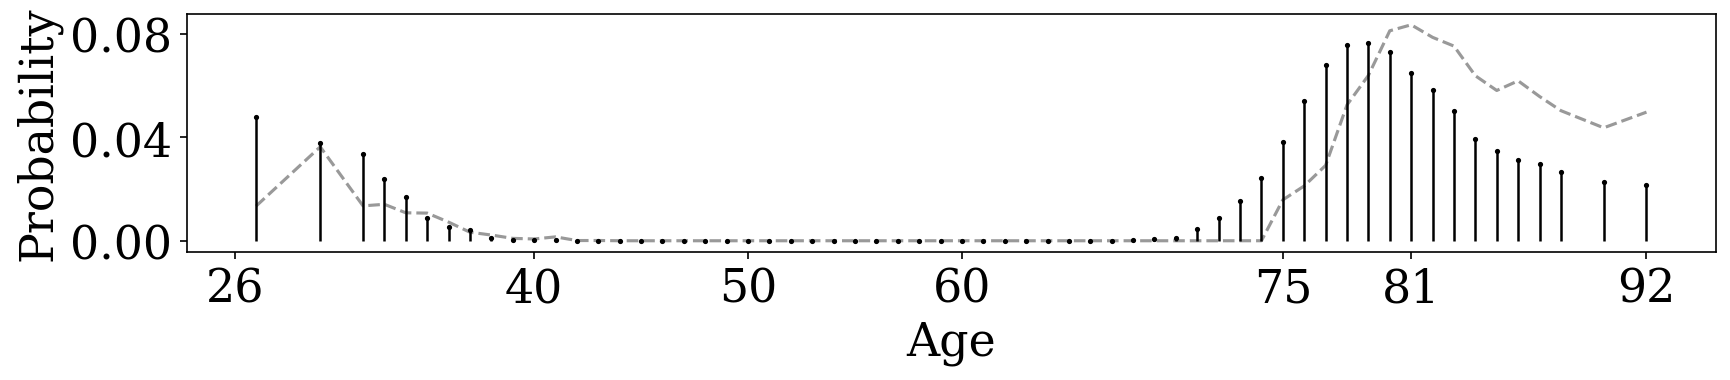

d1_least_squares_it30_q7_b40 l2_1e-06 P(1)= 0.11888573992035054 TV= 0.3867766527163242


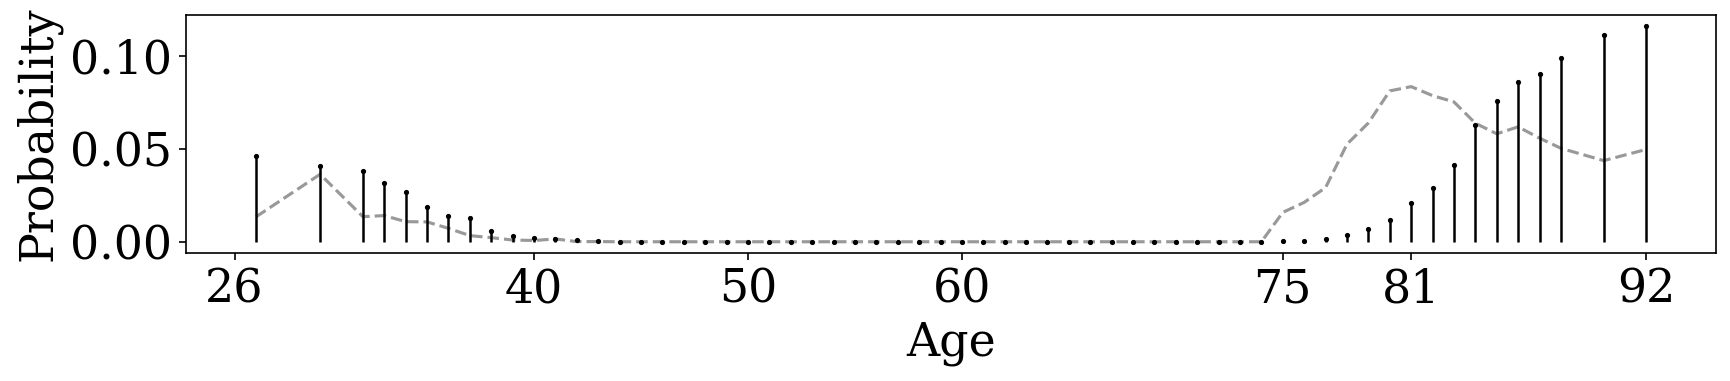

d85_least_squares_it30_q7_b40 l1_0.0001 P(1)= 0.1153303612512184 TV= 0.7359157767882094


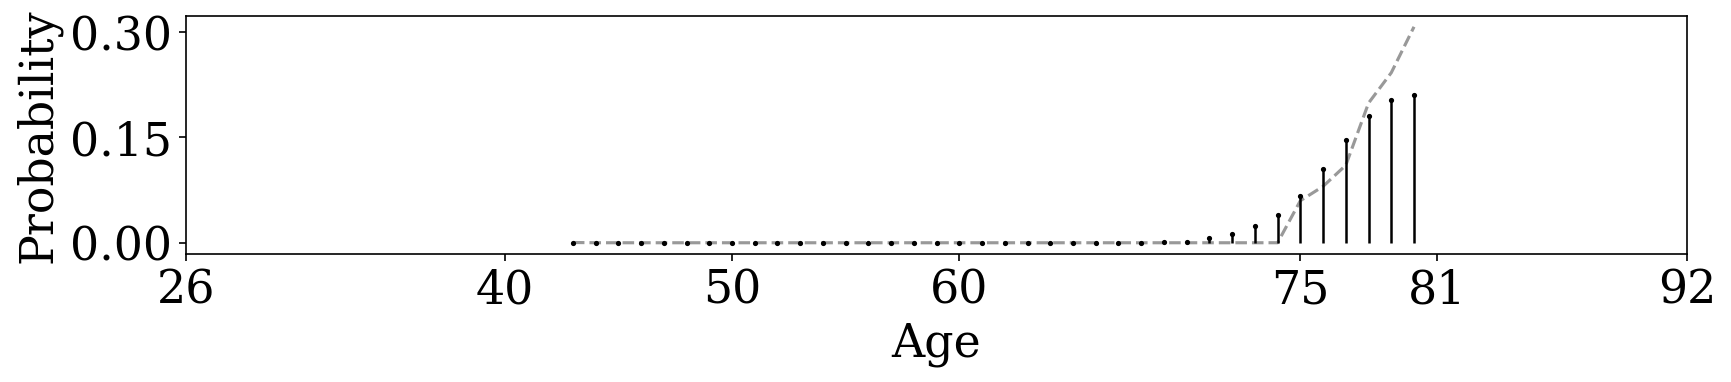

d85_least_squares_it-1_q7_b40 l1_0.0001 P(1)= 0.5068603557196733 TV= 0.8594232705440848


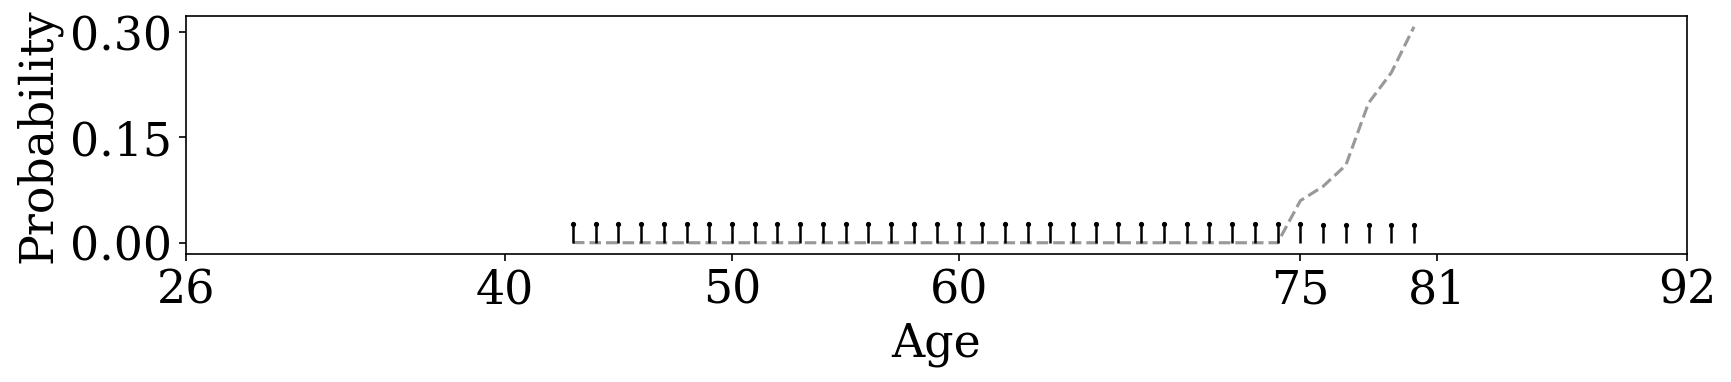

d1_l1_0.0001_it3_q7_b40 l2_1e-06 P(1)= 1.0000000000004499 TV= 0.879948733865907


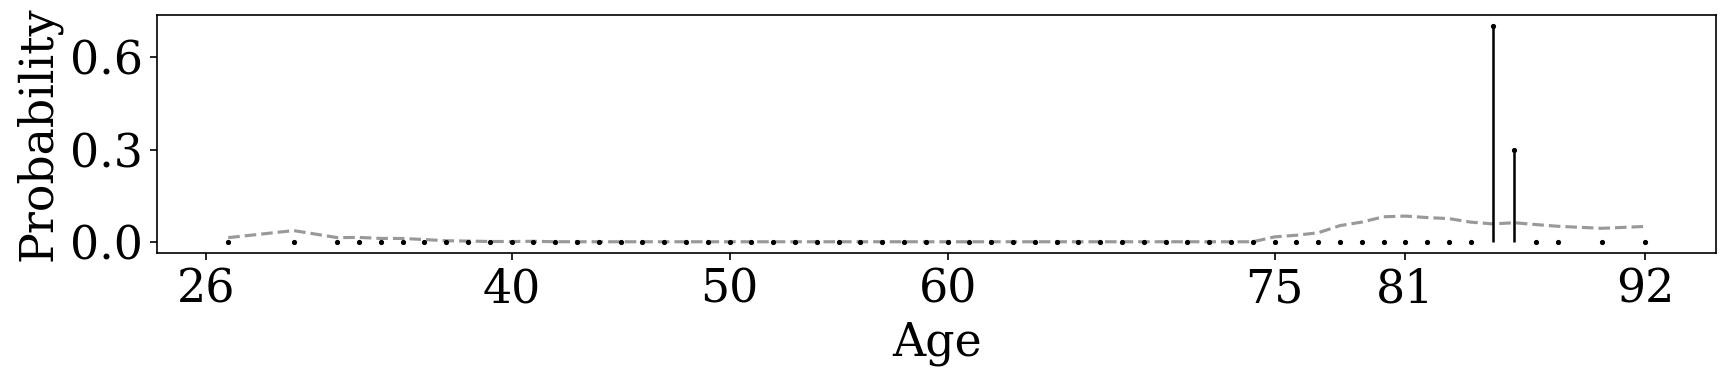

d85_least_squares_it10_q7_b40 l1_0.0001 P(1)= 0.9999999999982624 TV= 0.8833053002580881


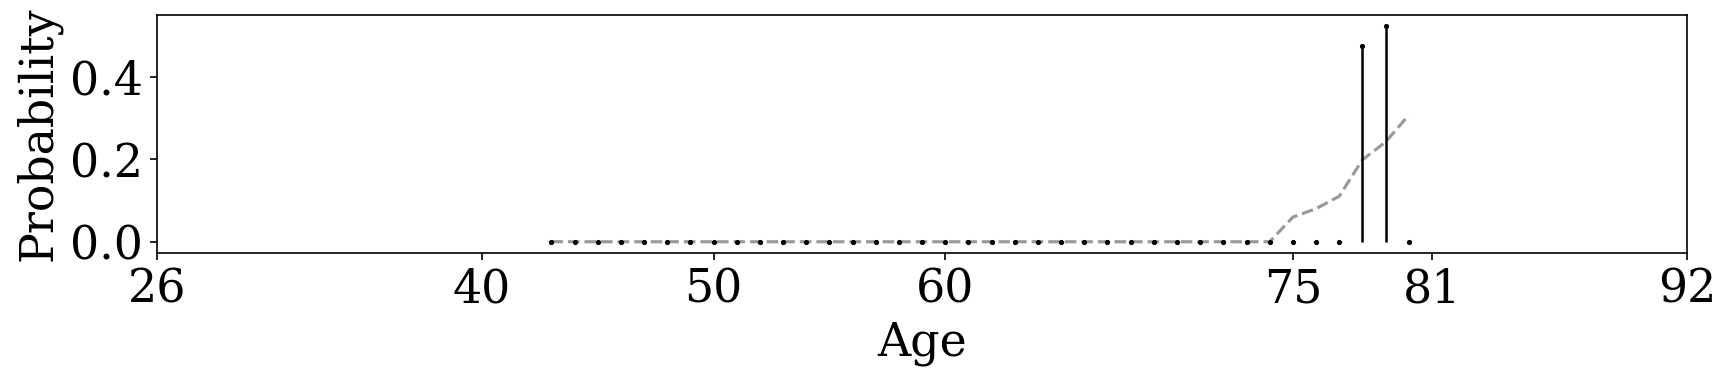

In [4]:

print('Closest curves: exploratory selection, not an independent validation.')
ranked=summary.sort_values('TV_to_reference').head(3)
qualifying=summary[summary.P_1>.5].sort_values('TV_to_reference').head(3)
for row in pd.concat([ranked,qualifying]).drop_duplicates(['setting','posterior_fit']).itertuples():
    rec=next(r for r in records if r['label']==row.setting)
    stats=rec['results'][row.posterior_fit];support=ages[rec['eta'][1:]]
    ref=np.array([reference_map.get(a,0.) for a in support]);ref/=ref.sum()
    print(row.setting,row.posterior_fit,'P(1)=',row.P_1,'TV=',row.TV_to_reference)
    with plt.rc_context({'font.size':22,'axes.labelsize':22,'xtick.labelsize':22,'ytick.labelsize':22}):
        fig,ax=plt.subplots(figsize=(12,3))
        ax.plot(support,ref,color='.6',ls='--',lw=1.5,label='Archived conditional')
        marker,stems,baseline=ax.stem(support,stats['conditional'],linefmt='k-',markerfmt='k.',basefmt=' ')
        plt.setp(stems,linewidth=1.2);plt.setp(marker,markersize=3)
        ax.set_xlabel('Age');ax.set_ylabel('Probability')
        ax.set_xticks([26,40,50,60,75,81,92]);ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
        fig.tight_layout();plt.show()


Minimum segment length: 1 ; posterior fit: l2_1e-08


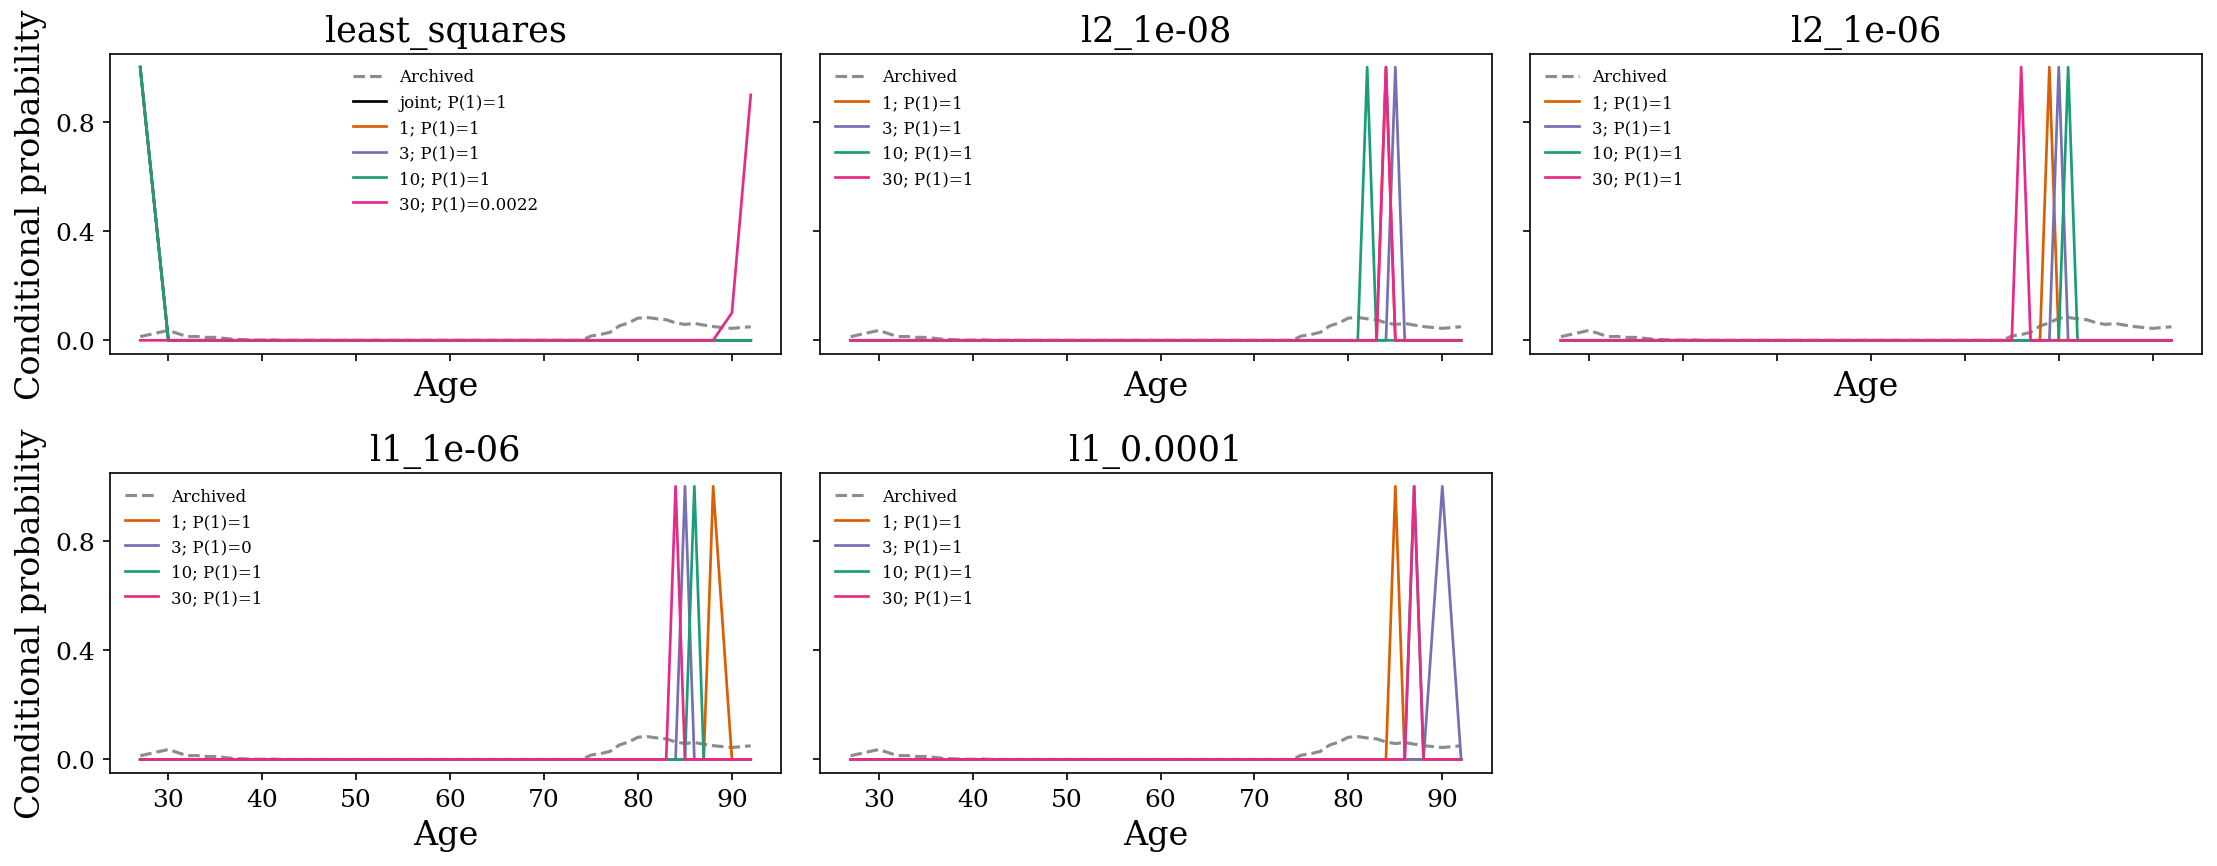

Minimum segment length: 1 ; posterior fit: l2_1e-06


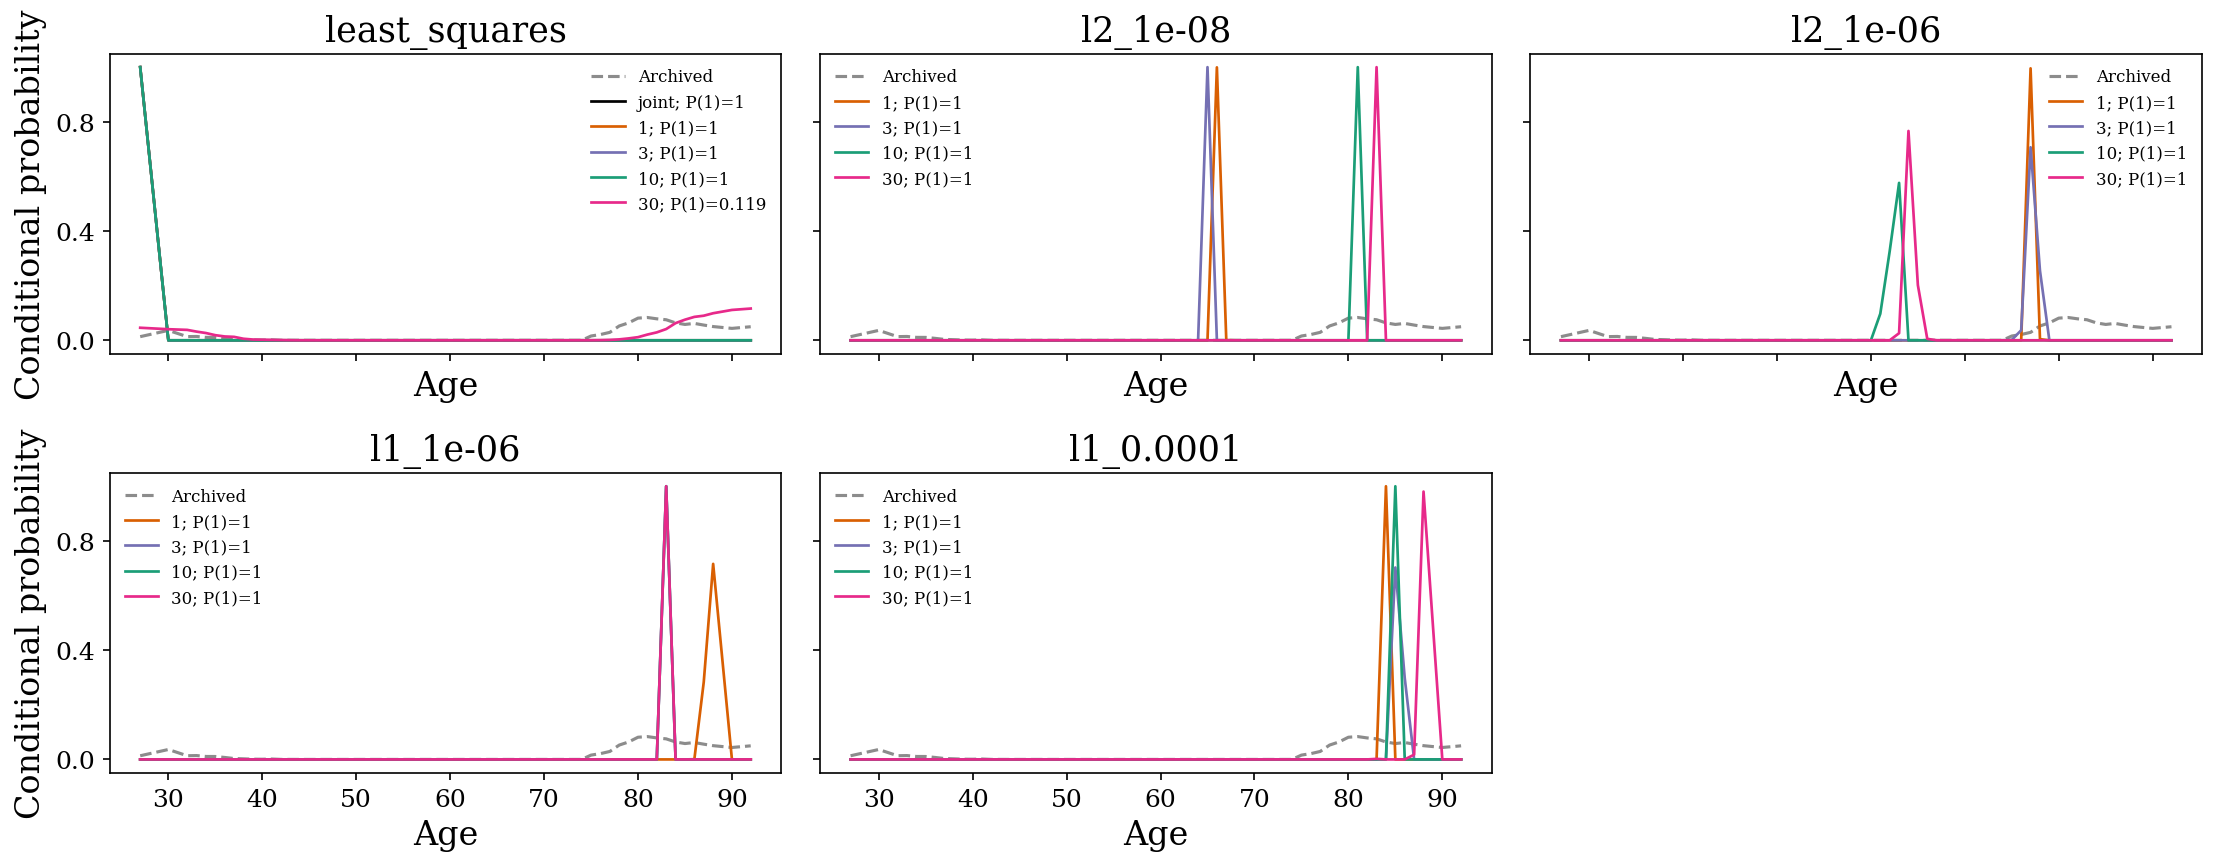

Minimum segment length: 1 ; posterior fit: l1_1e-06


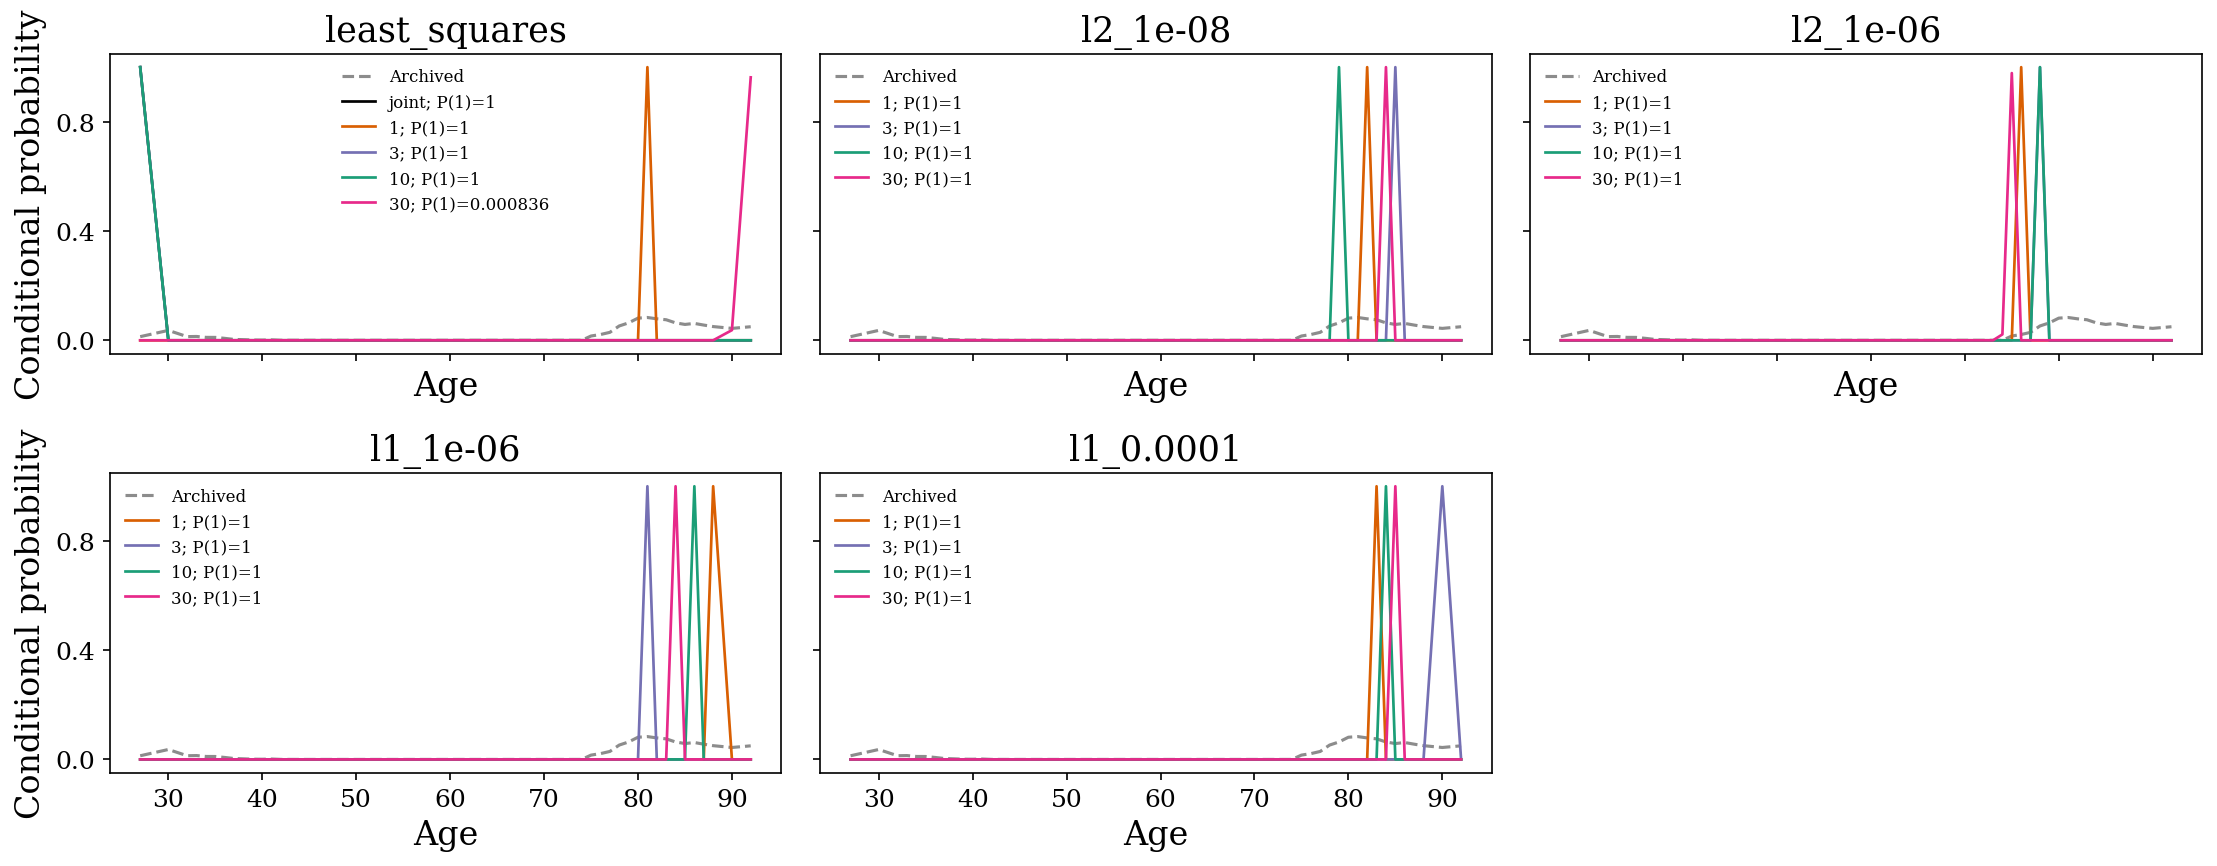

Minimum segment length: 1 ; posterior fit: l1_0.0001


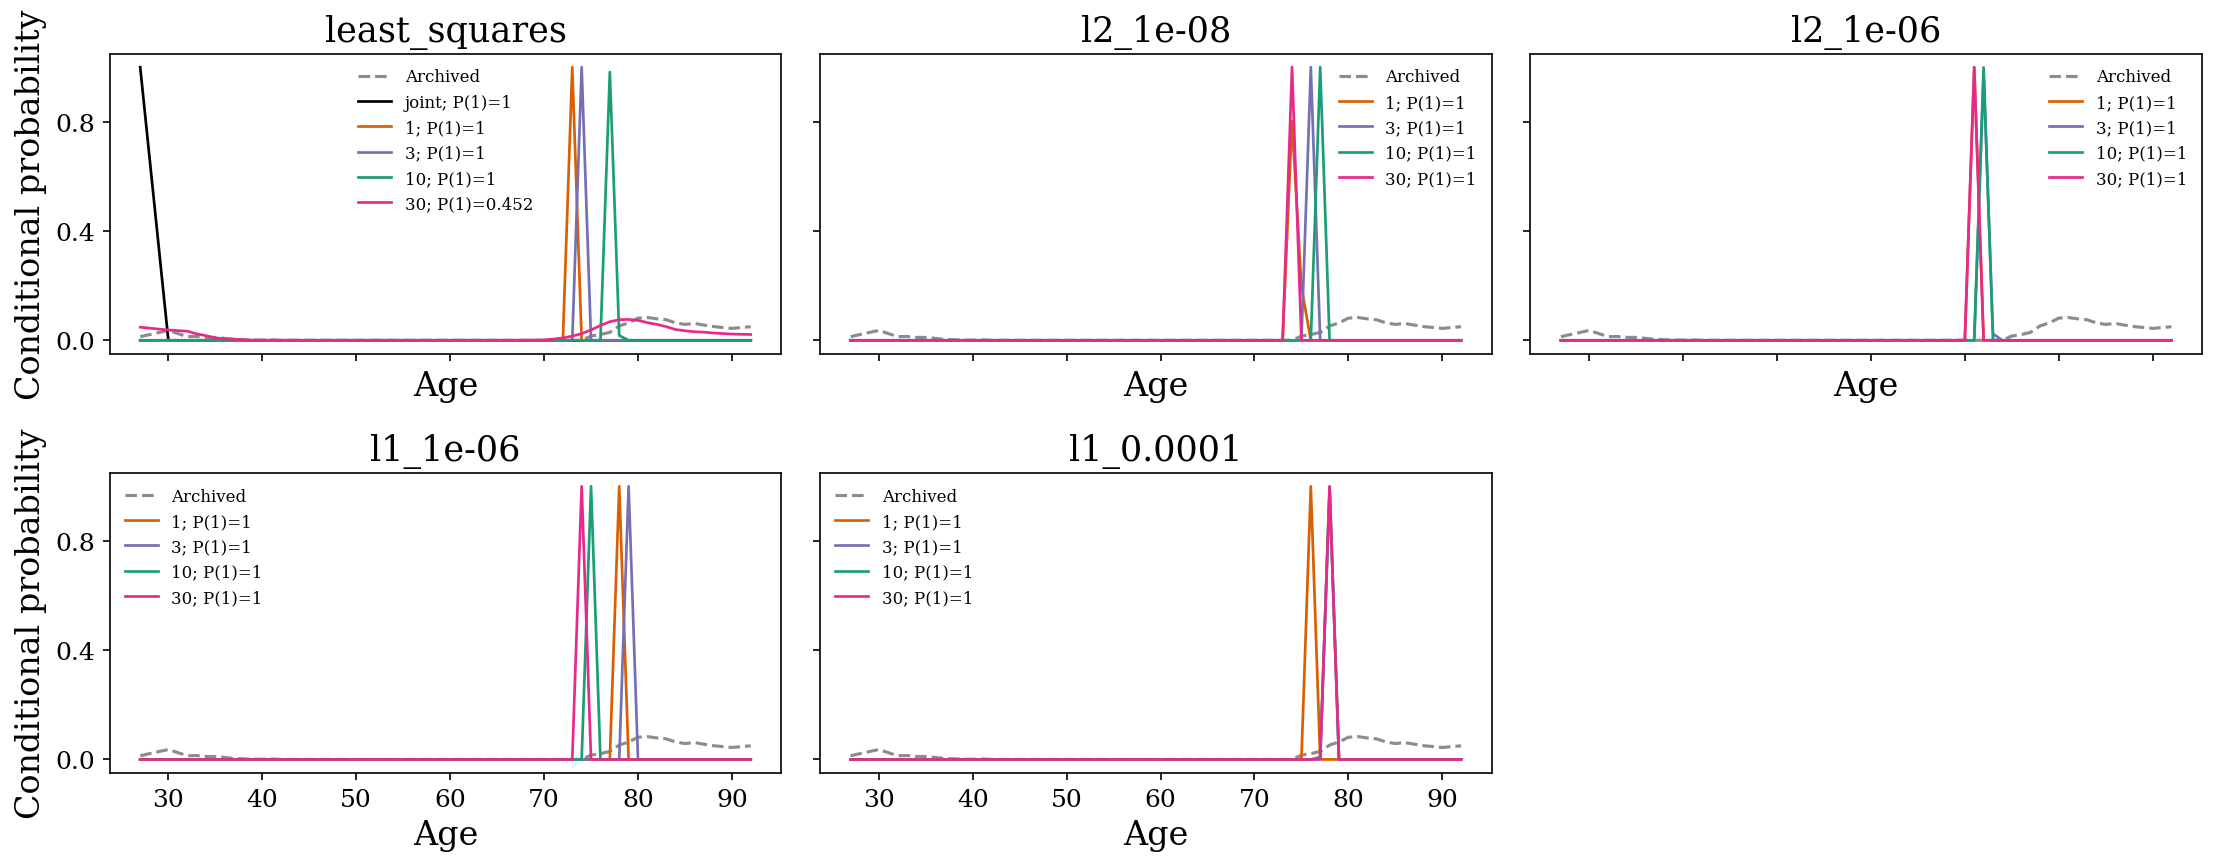

Minimum segment length: 85 ; posterior fit: l2_1e-08


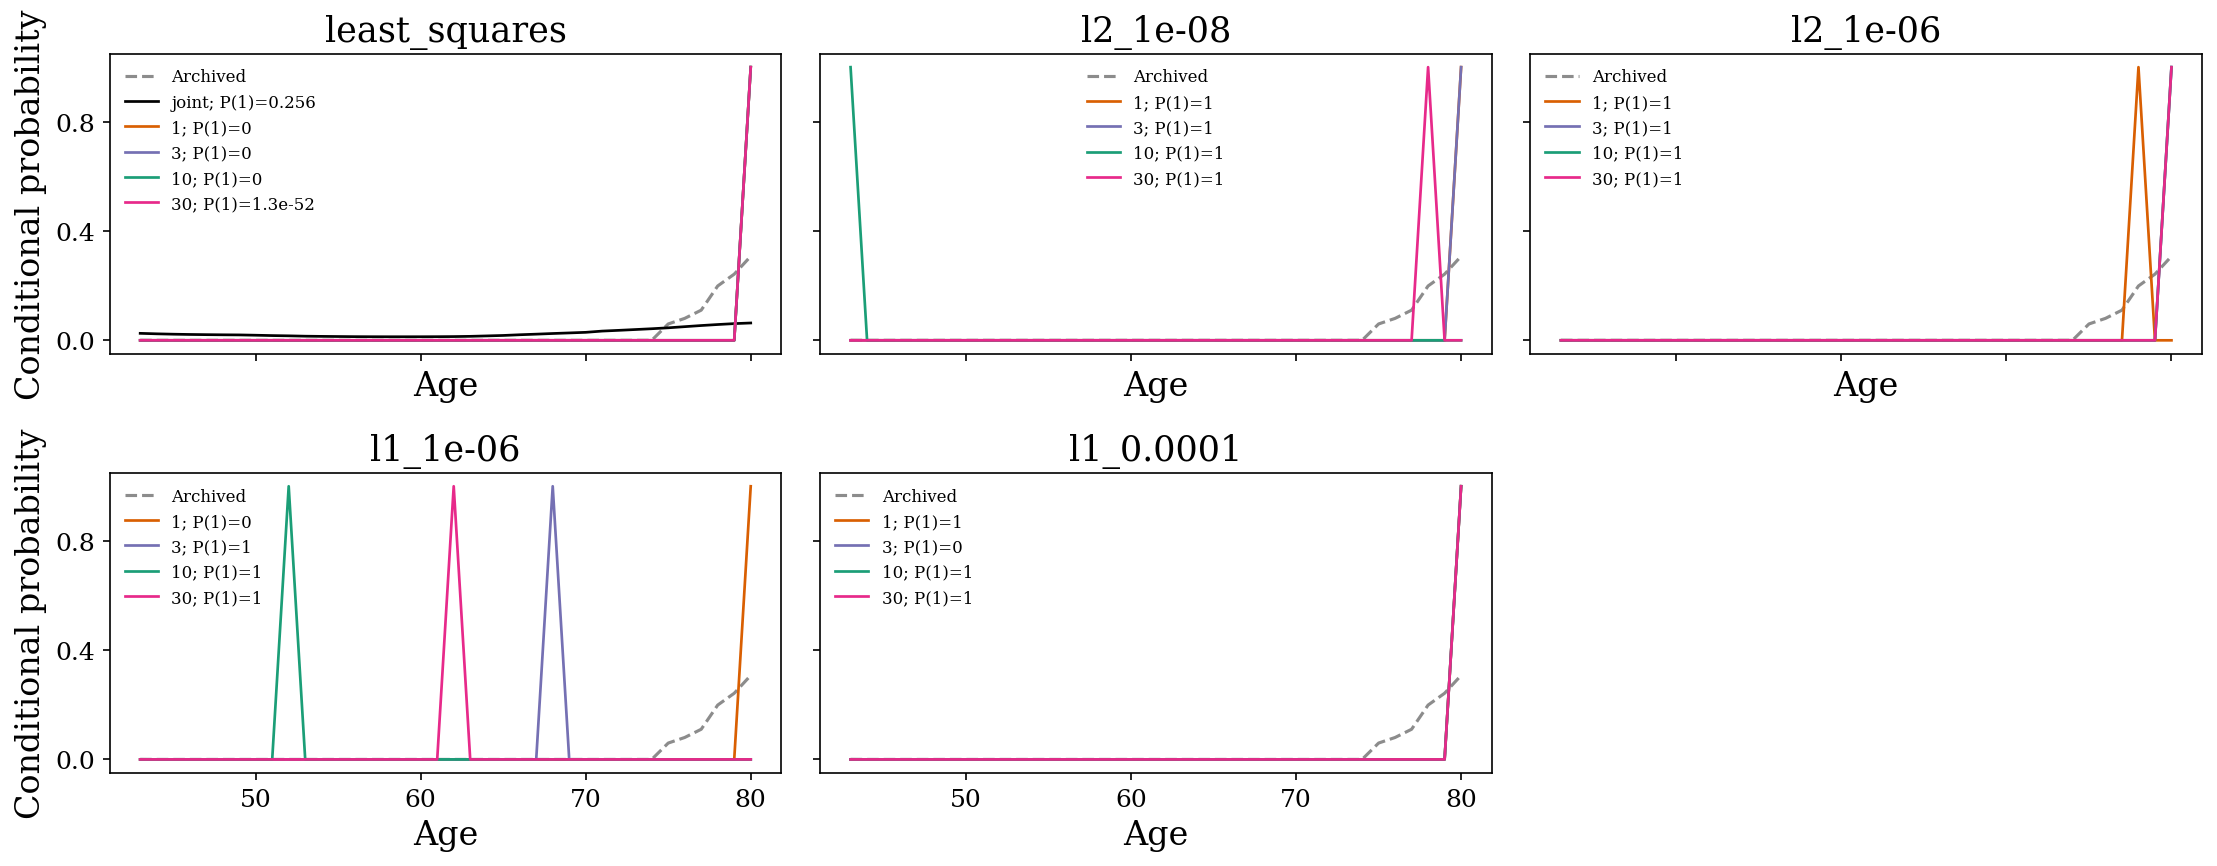

Minimum segment length: 85 ; posterior fit: l2_1e-06


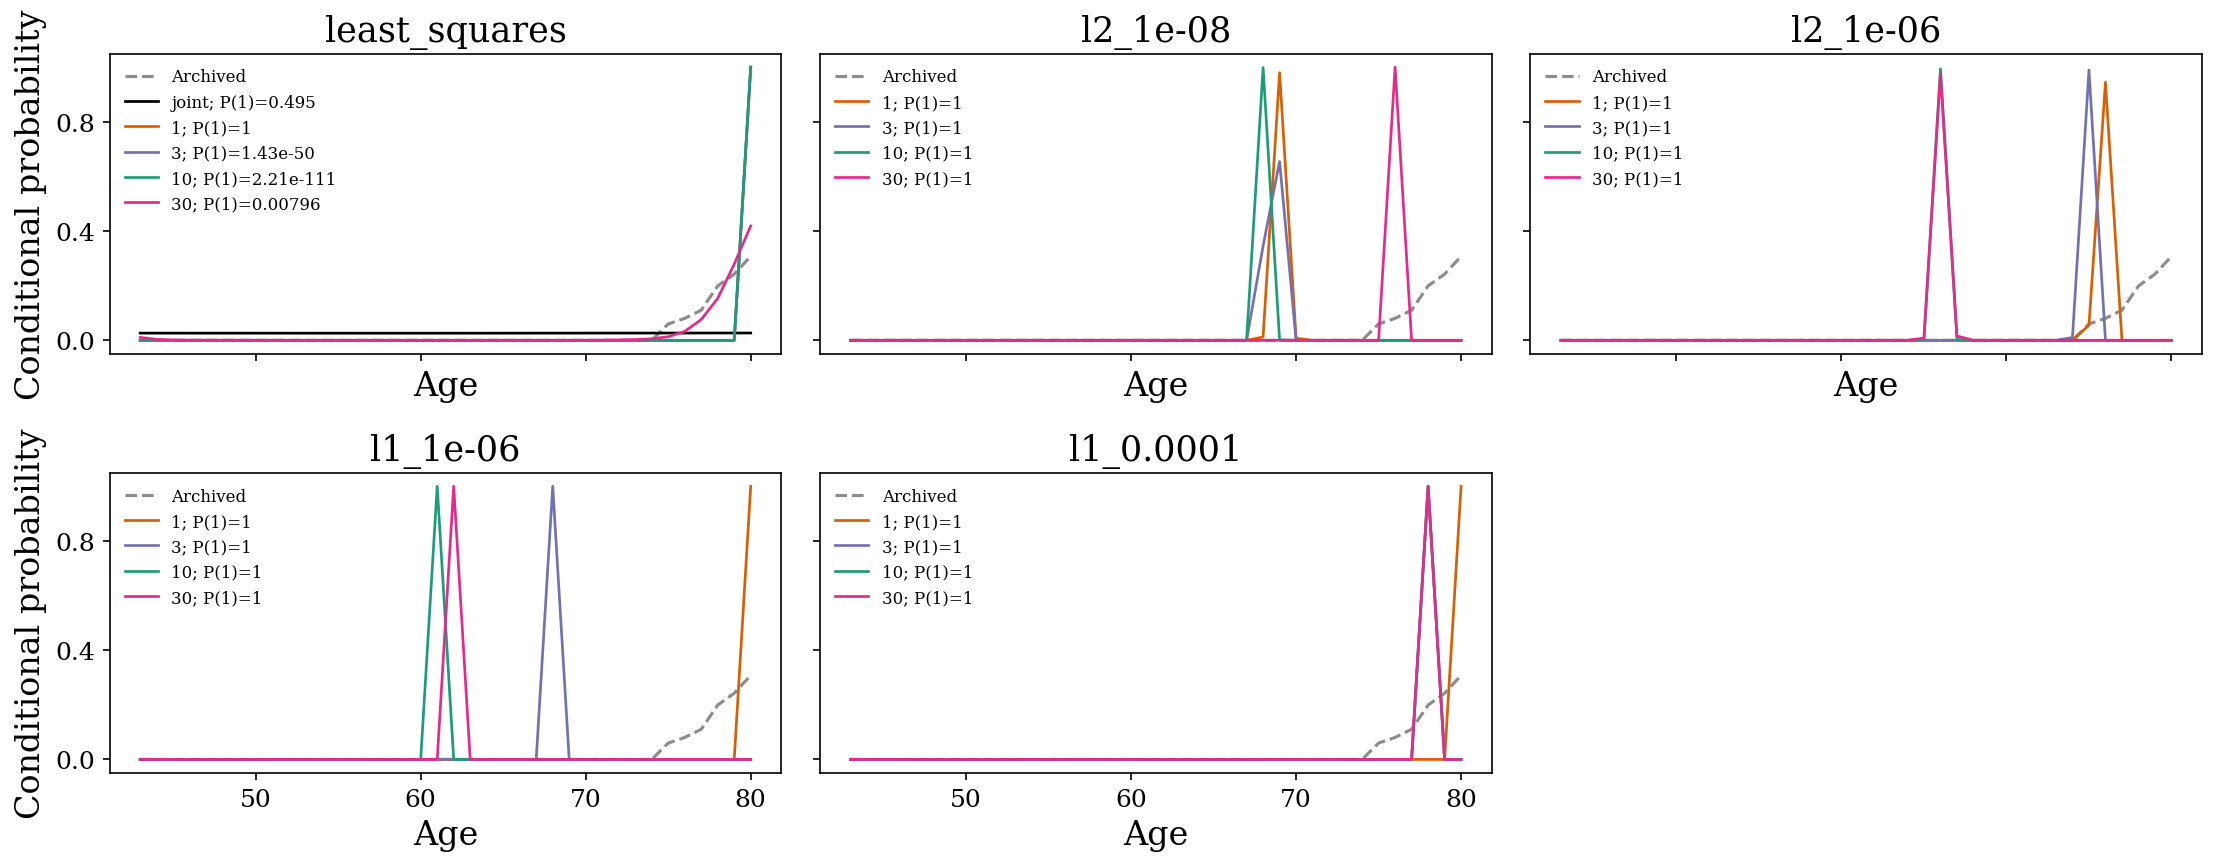

Minimum segment length: 85 ; posterior fit: l1_1e-06


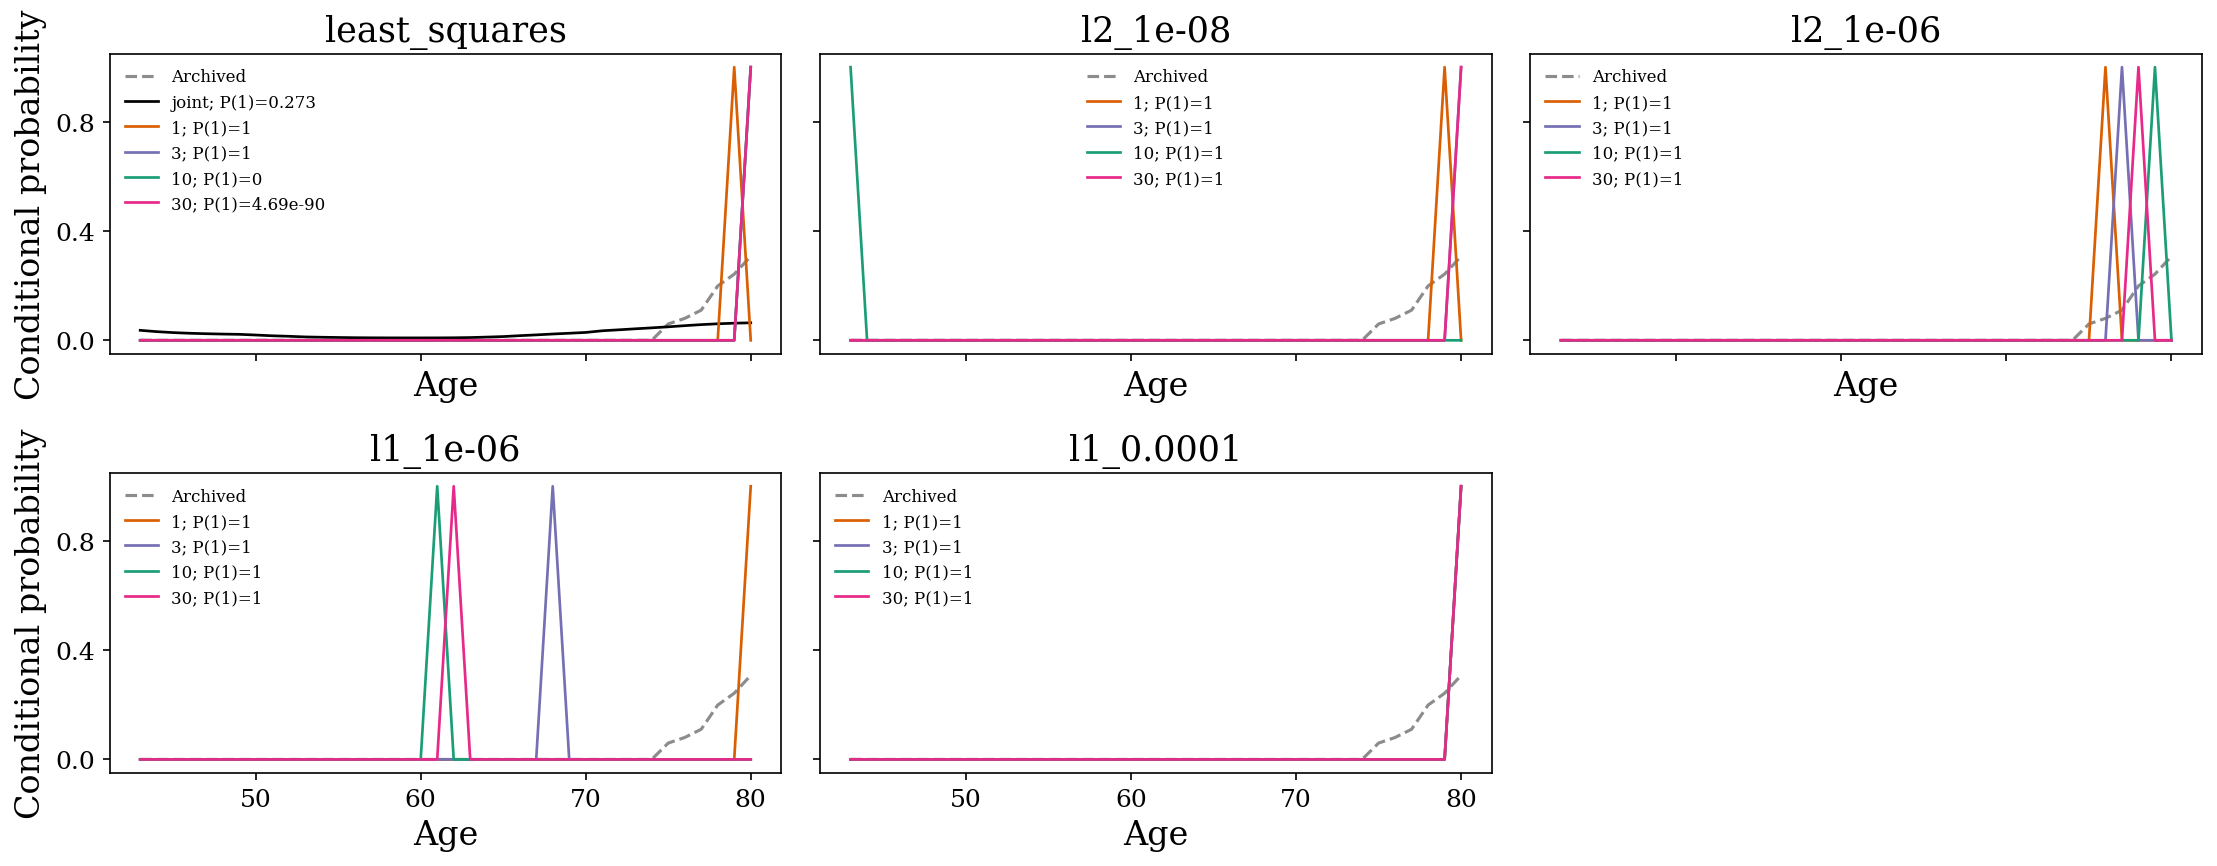

Minimum segment length: 85 ; posterior fit: l1_0.0001


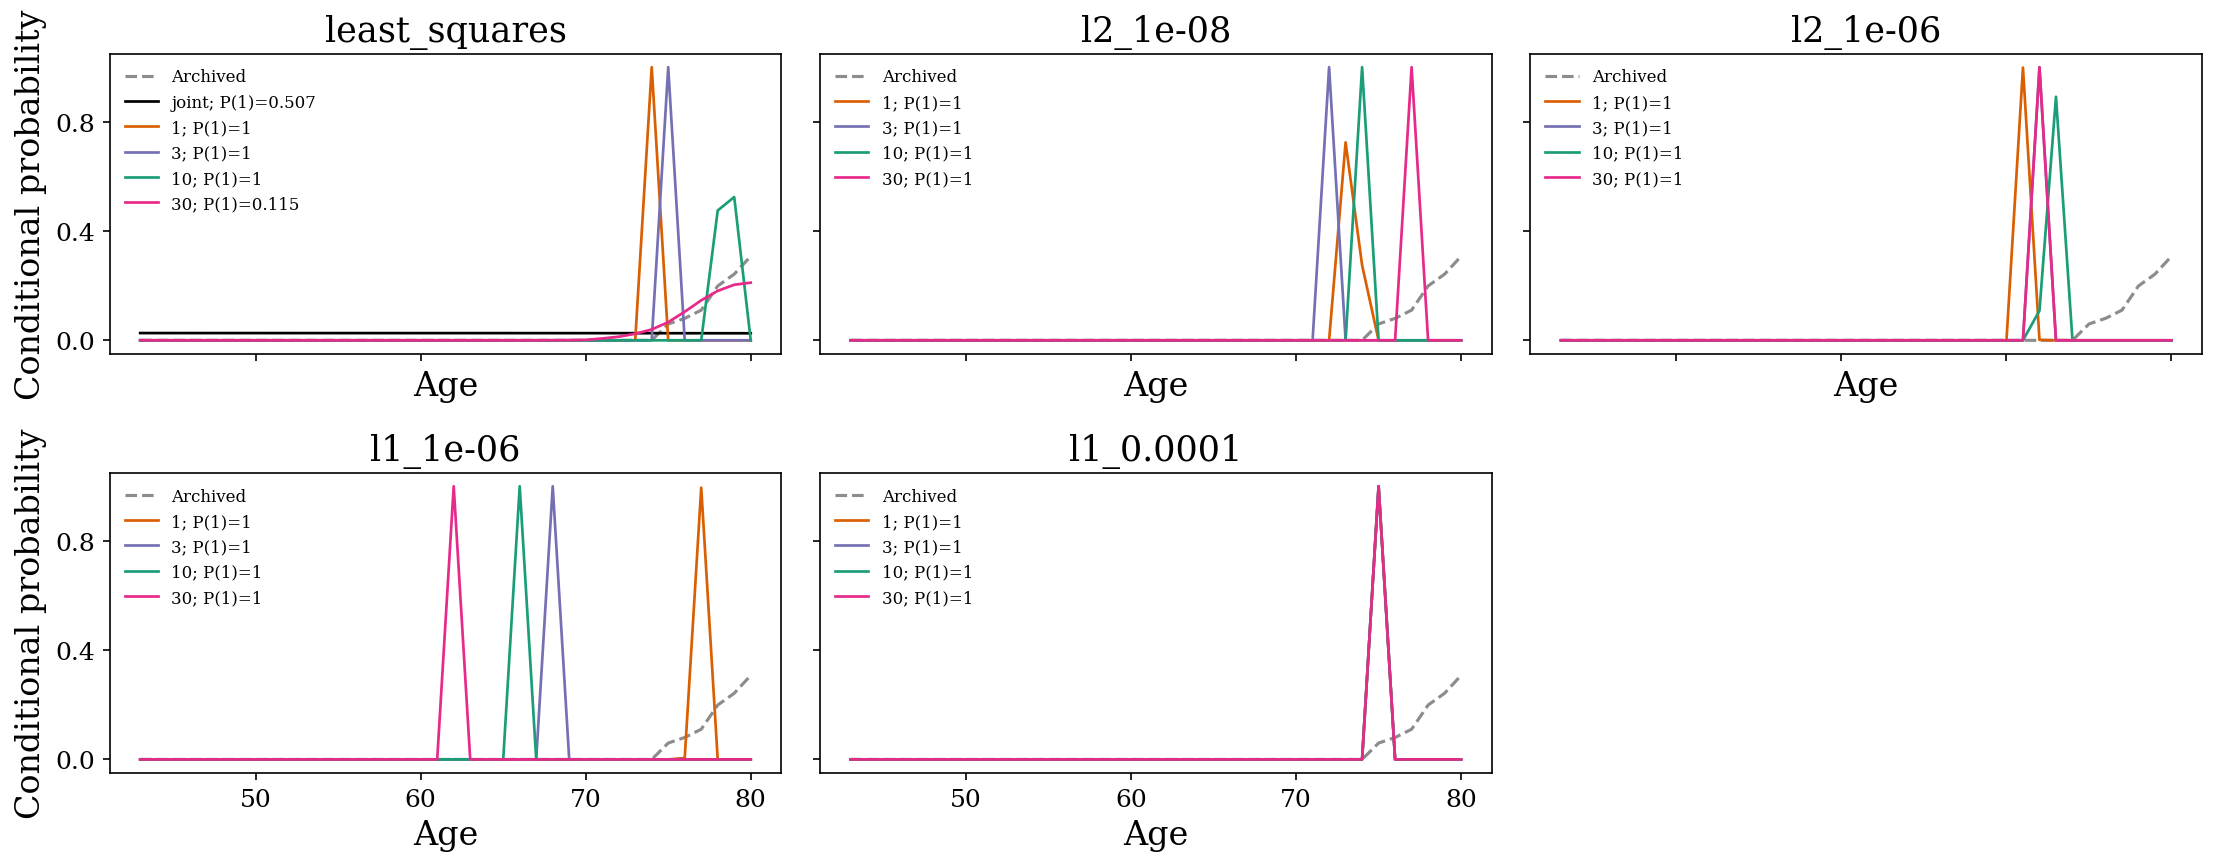

Minimum segment length: 169 ; posterior fit: l2_1e-08


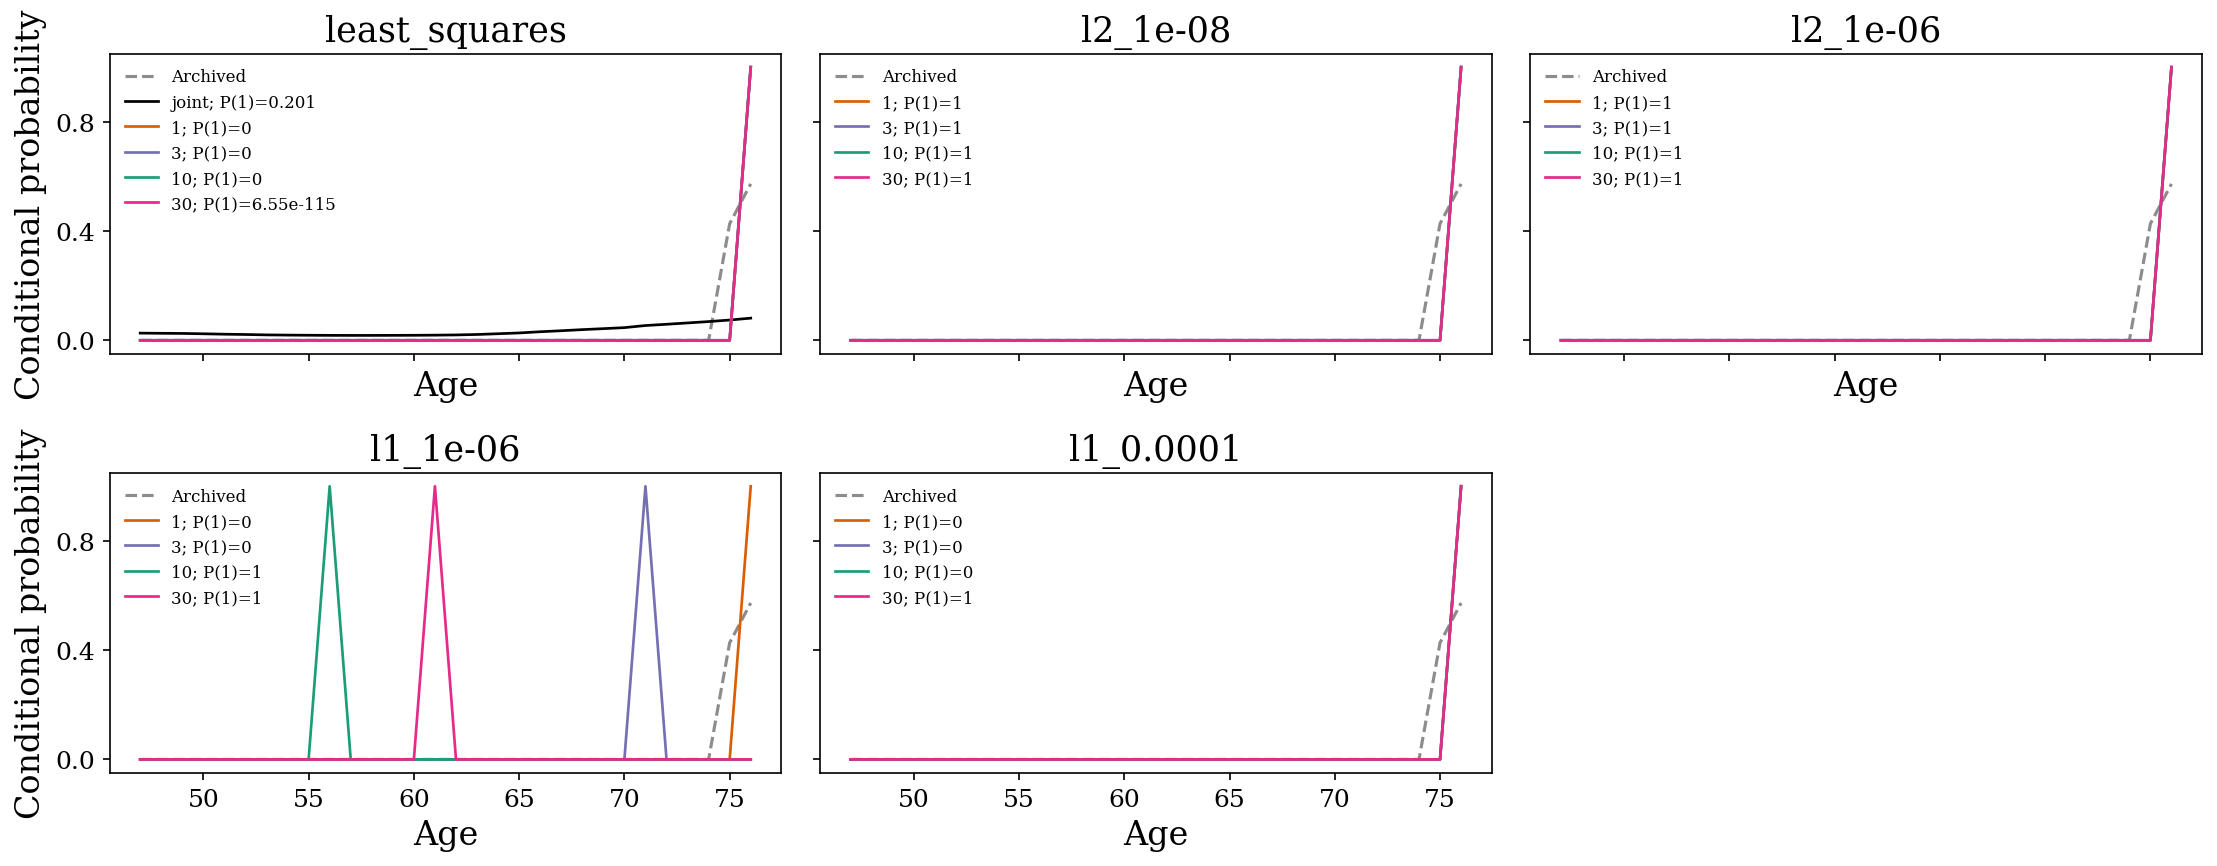

Minimum segment length: 169 ; posterior fit: l2_1e-06


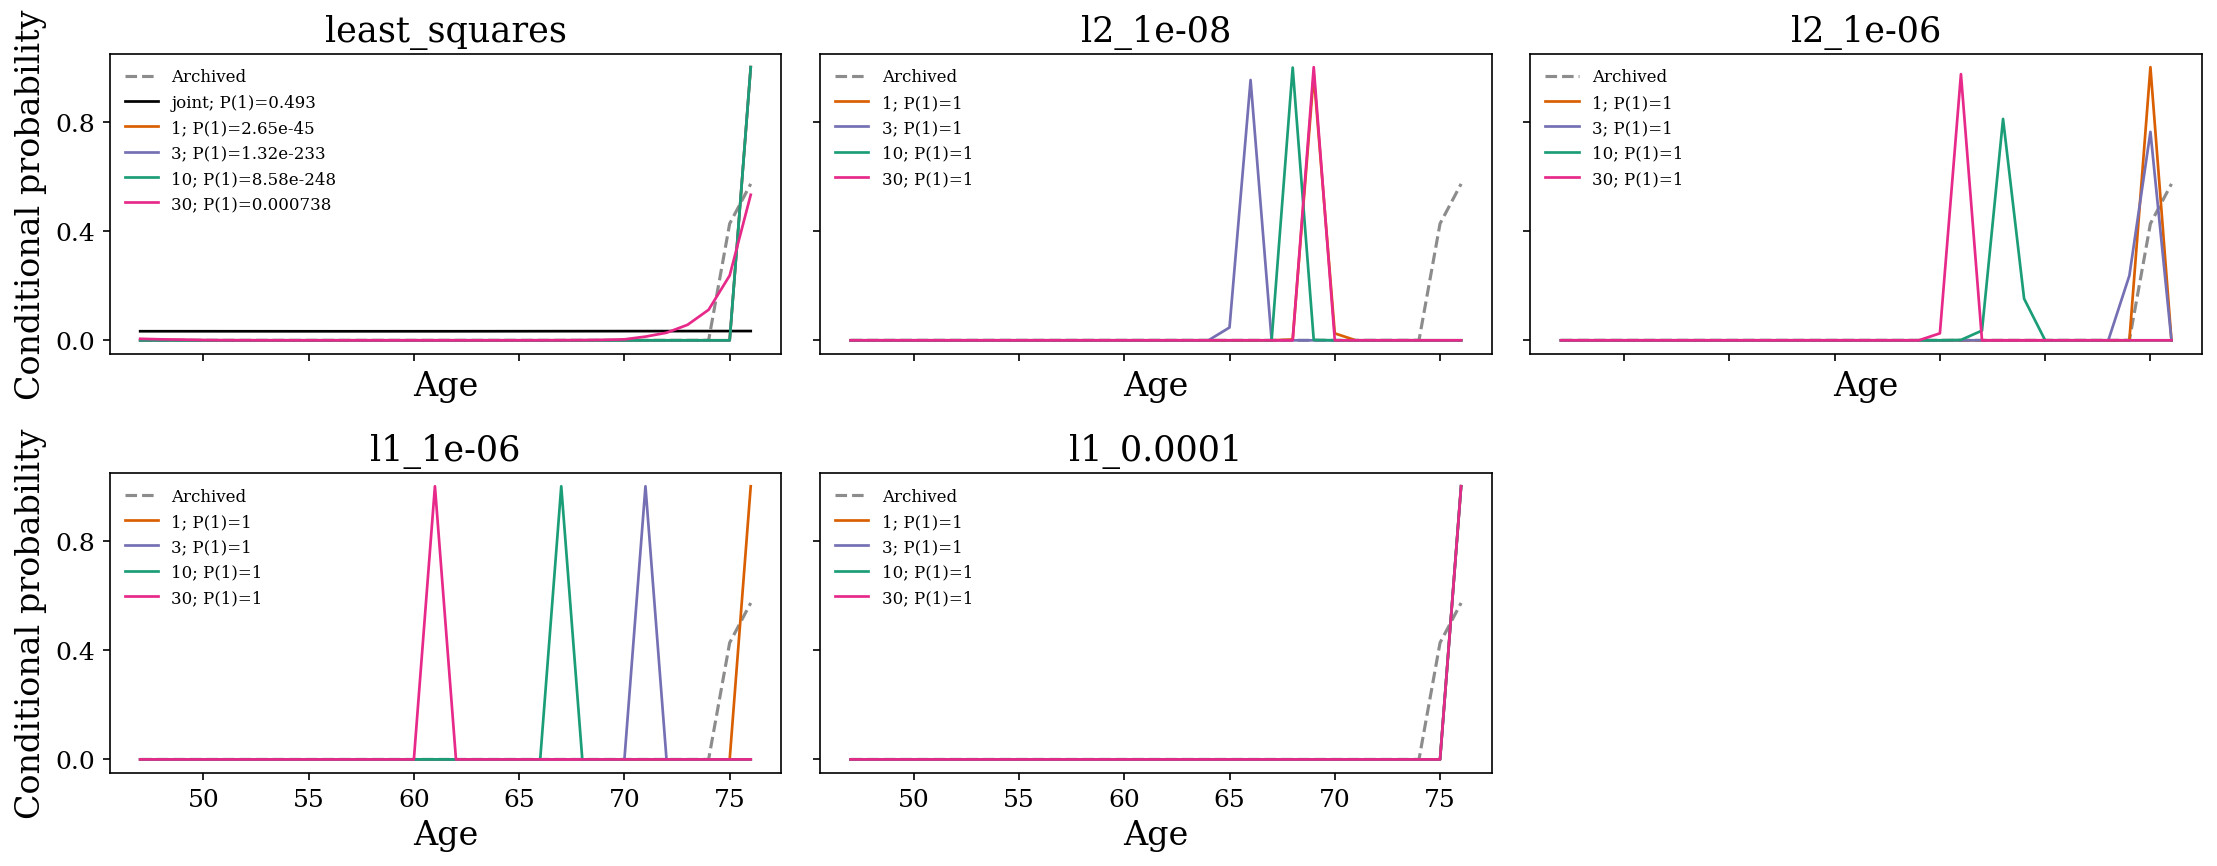

Minimum segment length: 169 ; posterior fit: l1_1e-06


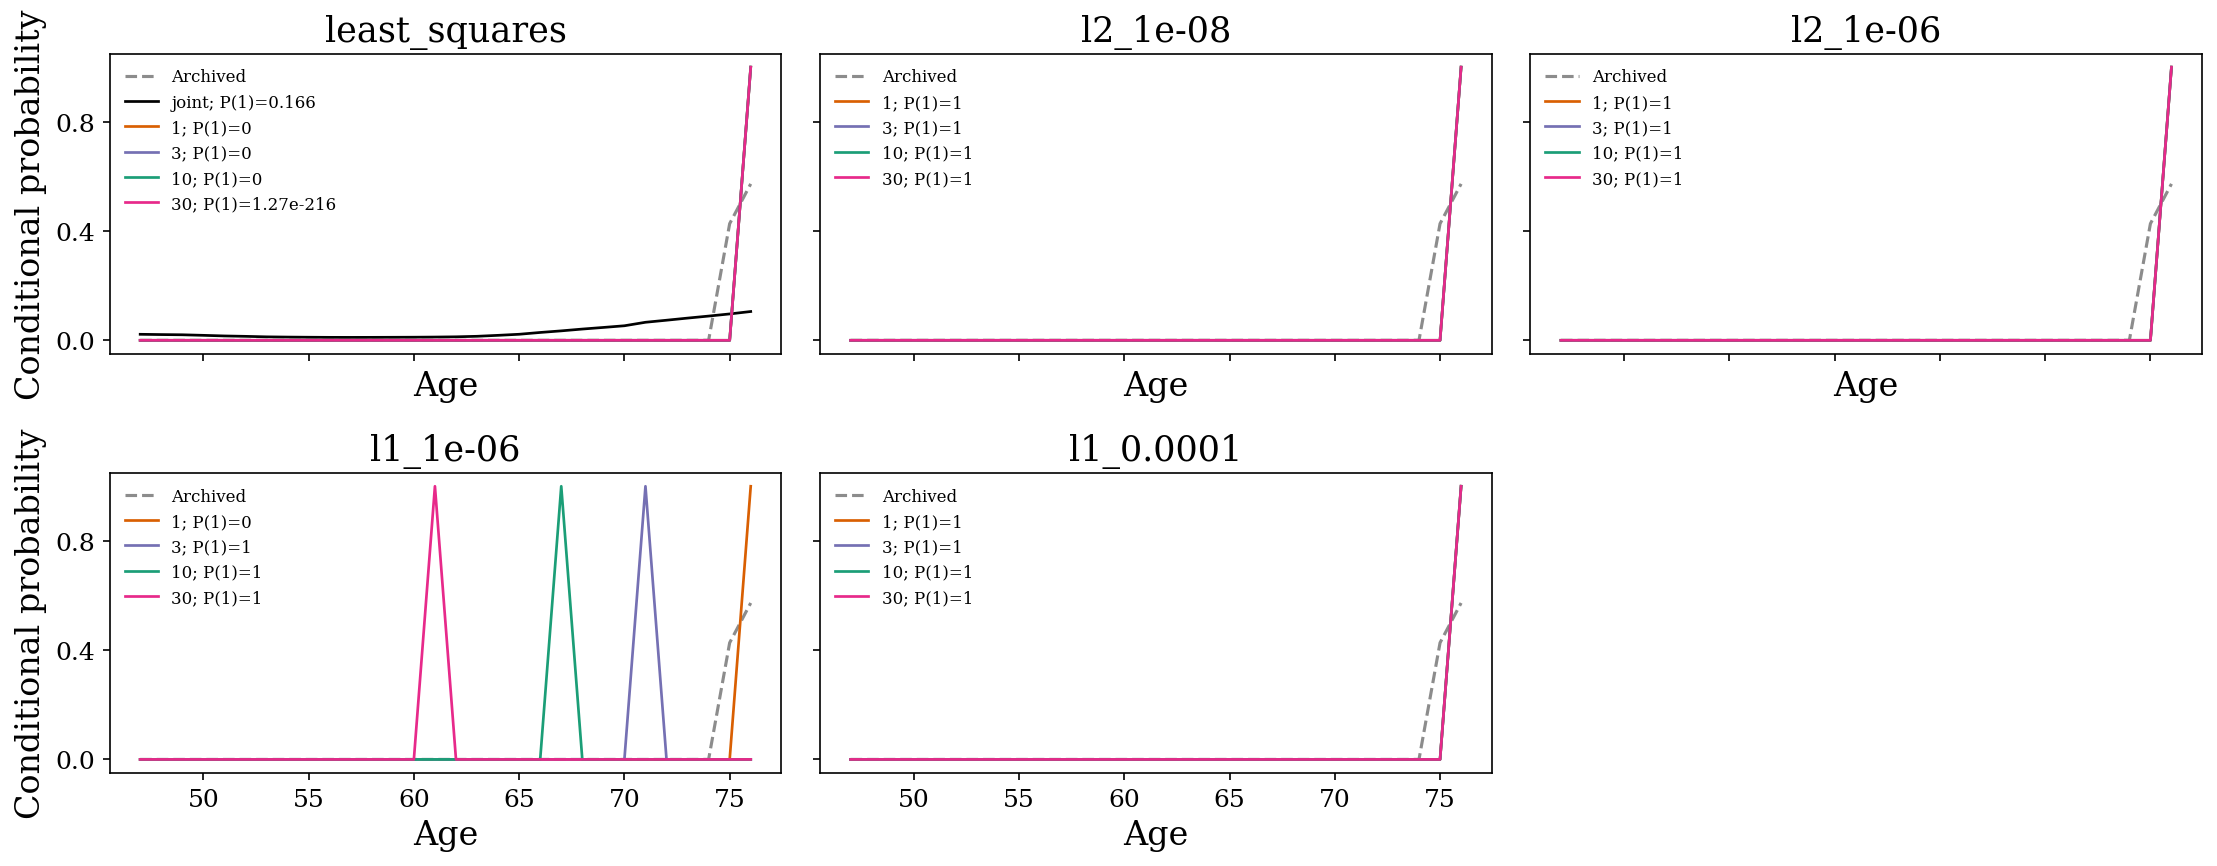

Minimum segment length: 169 ; posterior fit: l1_0.0001


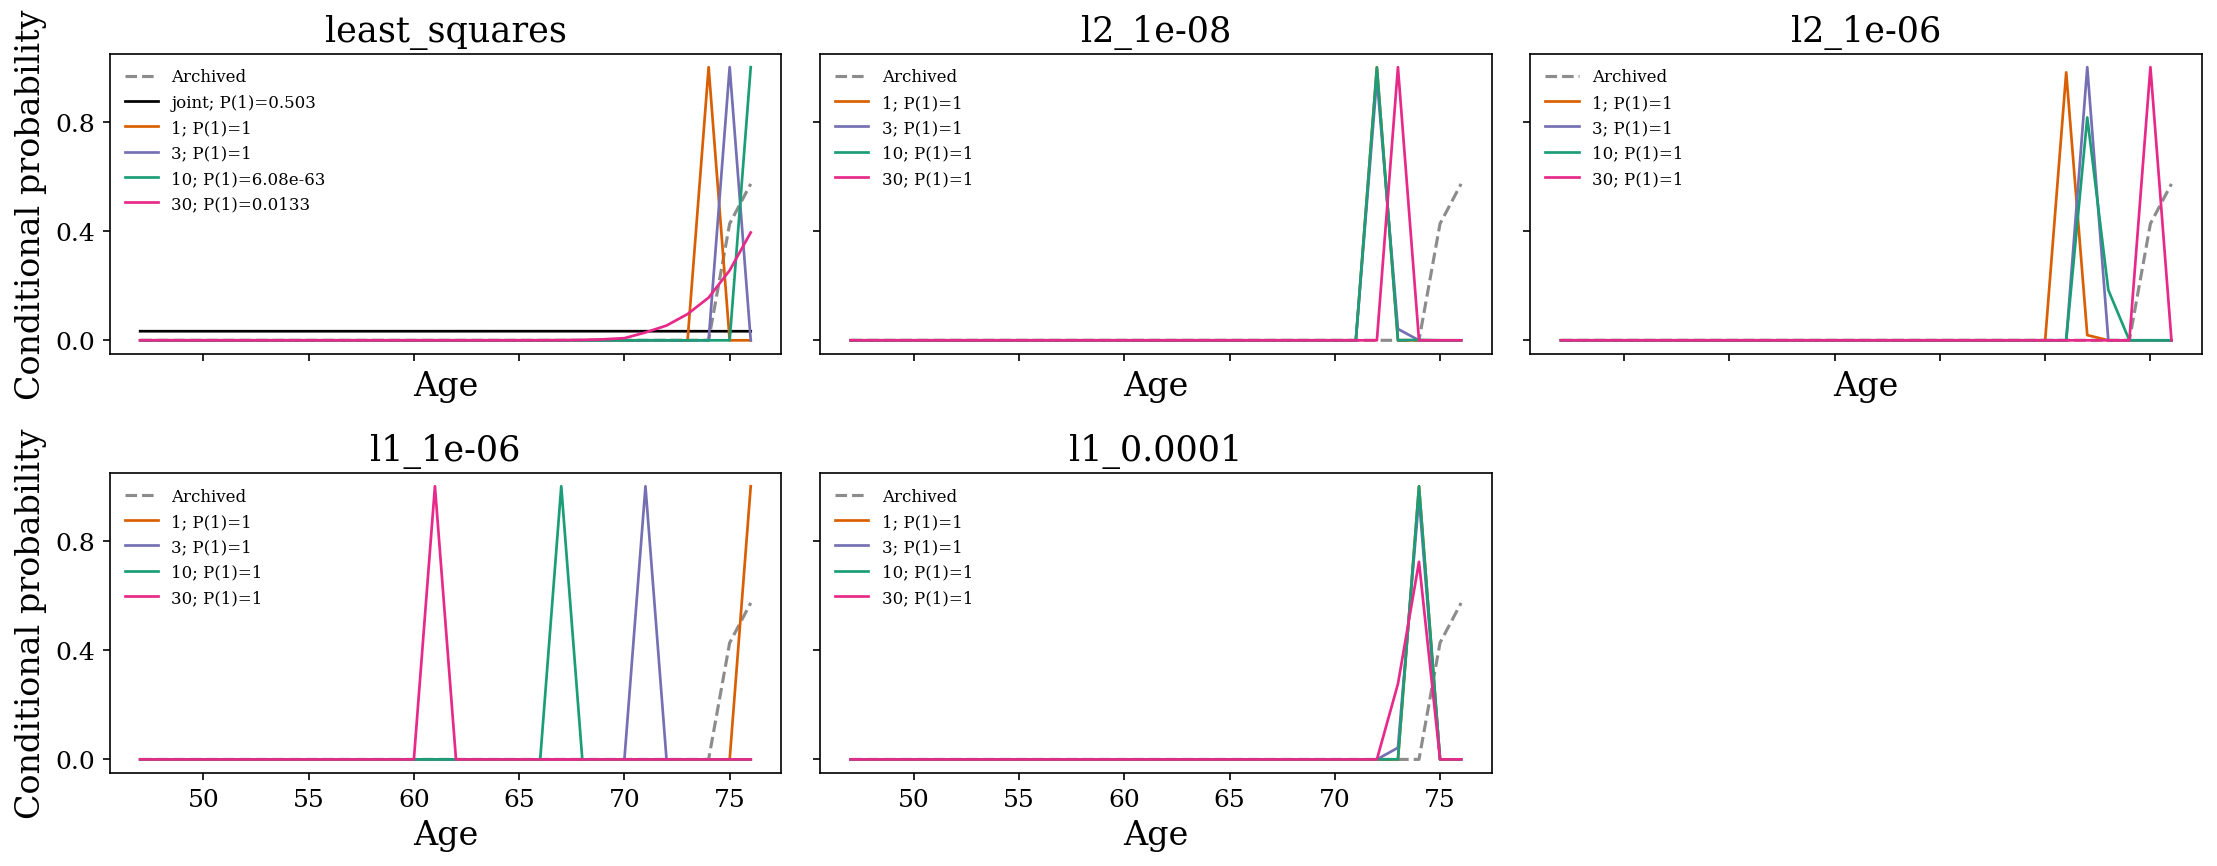

In [5]:

colors={1:'#d95f02',3:'#7570b3',10:'#1b9e77',30:'#e7298a',-1:'black'}
for d in DELTAS:
    for fit in (f'{k}_{v:g}' for k,v in FIT_SETTINGS):
        print('Minimum segment length:',d,'; posterior fit:',fit)
        fig,axes=plt.subplots(2,3,figsize=(15,6),sharex=True,sharey=True)
        for ax,aux in zip(axes.flat,['least_squares']+[f'{k}_{v:g}' for k,v in FIT_SETTINGS]):
            subset=[r for r in records if r['delta_min']==d and r['scenario']['auxiliary']==aux]
            if not subset:continue
            support=ages[subset[0]['eta'][1:]]
            ref=np.array([reference_map.get(a,0.) for a in support]);ref/=ref.sum()
            ax.plot(support,ref,color='.55',ls='--',lw=1.5,label='Archived')
            for rec in sorted(subset,key=lambda r:r['scenario']['iteration']):
                it=rec['scenario']['iteration'];stats=rec['results'][fit]
                ax.plot(support,stats['conditional'],color=colors[it],lw=1.3,
                    label=('joint' if it==-1 else str(it))+f"; P(1)={stats['presence']:.3g}")
            ax.set_title(aux);ax.set_xlabel('Age');ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
            ax.legend(fontsize=8,frameon=False)
        axes[0,0].set_ylabel('Conditional probability');axes[1,0].set_ylabel('Conditional probability')
        axes.flat[-1].axis('off');fig.tight_layout();plt.show()


## Count probability and residual sensitivity
No setting is hidden because it has a nonzero equation residual or an undesired count posterior. A small state-equation residual alone does not establish moment fit or model adequacy.

Minimum segment length: 1


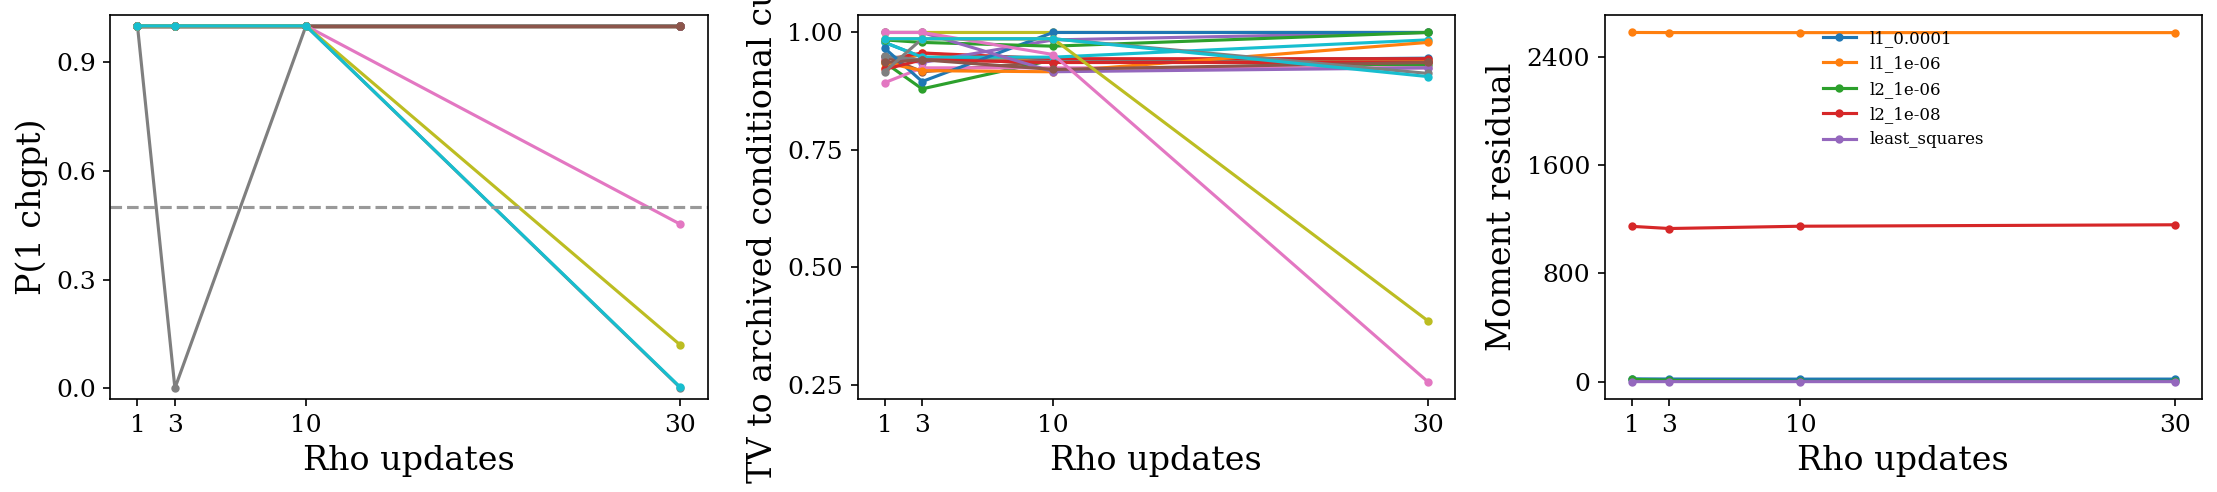

Minimum segment length: 85


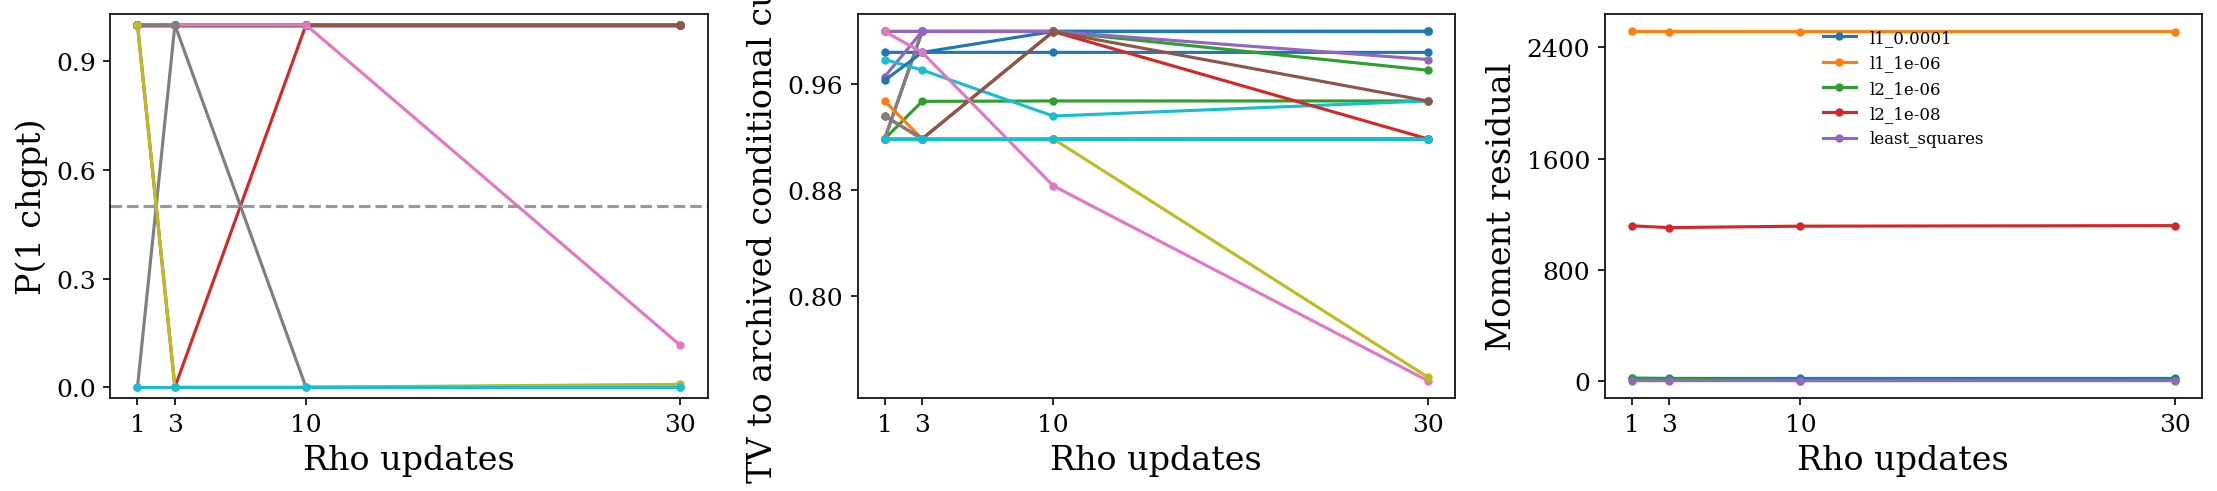

Minimum segment length: 169


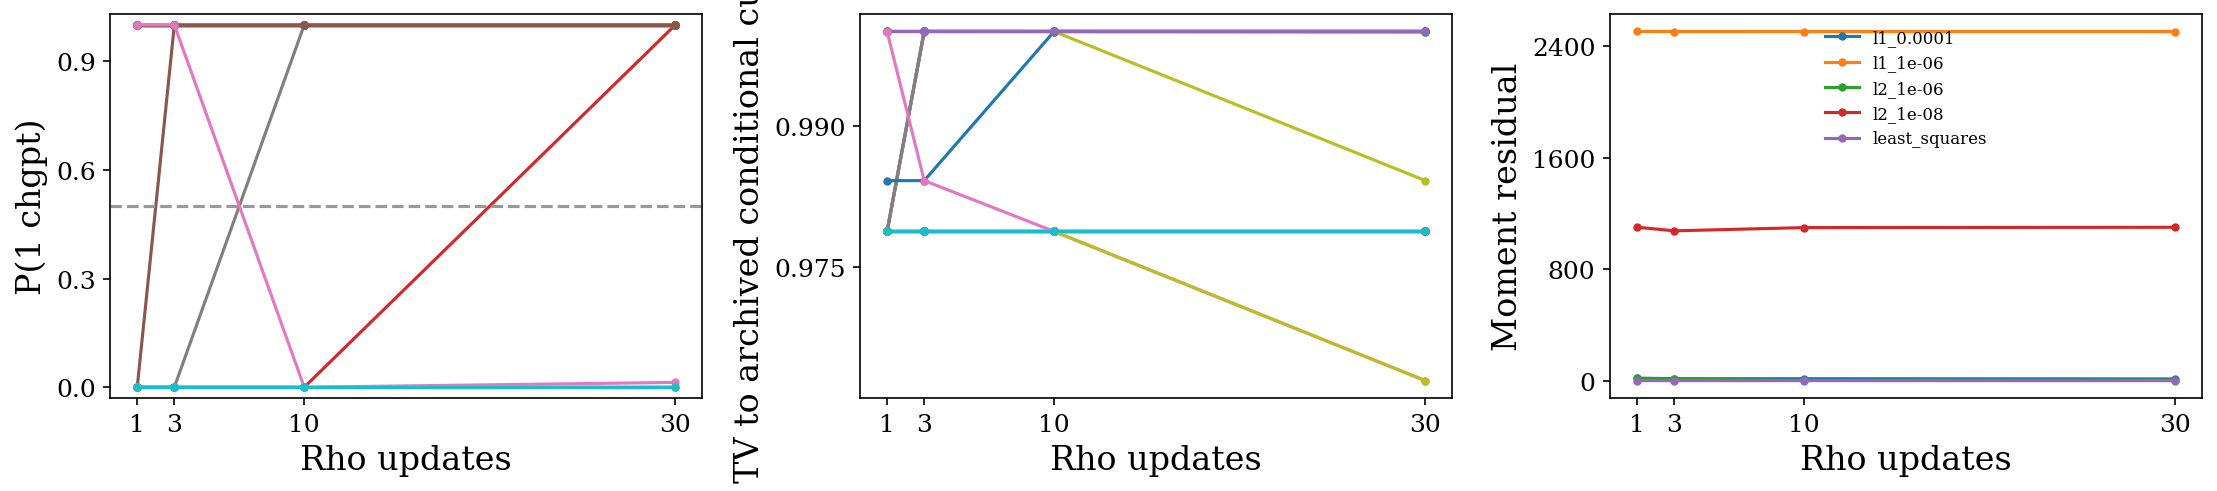

In [6]:

for d in DELTAS:
    print('Minimum segment length:',d)
    fig,axes=plt.subplots(1,3,figsize=(15,3.5))
    subset=summary[(summary.Delta==d)&(summary.iterations>0)]
    for (aux,fit),part in subset.groupby(['auxiliary','posterior_fit']):
        part=part.sort_values('iterations');label=aux+' / '+fit
        axes[0].plot(part.iterations,part.P_1,'.-',label=label)
        axes[1].plot(part.iterations,part.TV_to_reference,'.-')
    for aux,part in subset.drop_duplicates(['auxiliary','iterations']).groupby('auxiliary'):
        part=part.sort_values('iterations');axes[2].plot(part.iterations,part.moment_residual,'.-',label=aux)
    axes[0].axhline(.5,color='.6',ls='--');axes[0].set_ylabel('P(1 chgpt)');axes[0].set_ylim(-.03,1.03)
    axes[1].set_ylabel('TV to archived conditional curve');axes[2].set_ylabel('Moment residual')
    axes[2].legend(fontsize=8,frameon=False)
    for ax in axes:ax.set_xlabel('Rho updates');ax.set_xticks(ITERATIONS);ax.yaxis.set_major_locator(ticker.MaxNLocator(4))
    fig.tight_layout();plt.show()


## Numerical-budget sensitivity and likelihood decomposition

The cases below were specified without consulting posterior outcomes: all five auxiliary fits at
3 and 30 rho updates for $\Delta=1$, every LS update budget there, plus the joint LS approximation at each $\Delta$.
Compare the 128-draw/40-evaluation screen with 128/10 and 512/100. The conditional-only column
deliberately omits $p(V\mid\eta)$ to show its impact; it is a **diagnostic pseudo-posterior**, not
the primary joint posterior or a justification for selecting the desired count probability.


In [7]:
"""Declared numerical refinements and clearly separated scoring diagnostics."""

from scipy.stats import multivariate_normal
from scipy.special import ndtr, log_ndtr


def evaluate_refined(*args):
    import WERM.myocardial_approximate as implementation
    from WERM.myocardial_numerics import logistic_prox_fast
    original=implementation.logistic_prox
    implementation.logistic_prox=logistic_prox_fast
    try:return evaluate_scenario(*args)
    finally:implementation.logistic_prox=original


def compare_scores(root):
    """Compare joint vs conditional-observation scores without changing the fit.

    Conditional-only normalization is a diagnostic pseudo-posterior, not the
    audited joint posterior. It does not repair the original covariance error.
    """
    X,y,ages,locations=load_data();rows=[]
    for path in sorted(root.glob('d*_q7_b40.pkl')):
        rec=pickle.load(path.open('rb'))
        setting=pickle.load((root/f"fits_delta{rec['delta_min']}.pkl").open('rb'))
        for name,fit in setting['fits'].items():
            joint=rec['results'][name]['log_likelihood'];normal=[]
            for state in rec['states']:
                cov=state['lambda'].T@rec['scenario']['rho']@state['lambda']+state['kappa']
                normal.append(multivariate_normal.logpdf(fit['V'],mean=np.zeros(2),cov=cov).sum())
            conditional=joint-np.array(normal)
            logweights=conditional+np.log(setting['prior'])
            probabilities=np.exp(logweights-logsumexp(logweights))
            curve=np.exp(conditional[1:]-logsumexp(conditional[1:]))
            rows.append(dict(setting=rec['label'],posterior_fit=name,
                joint_P_1=rec['results'][name]['presence'],conditional_only_P_1=probabilities[1:].sum(),
                conditional_only_peak_age=ages[rec['eta'][1:][np.argmax(curve)]]))
    pd.DataFrame(rows).to_csv(root/'conditional_only_diagnostic.csv',index=False)


def refine(root):
    X,y,ages,locations=load_data()
    settings=[pickle.load((root/f'fits_delta{d}.pkl').open('rb')) for d in DELTAS]
    # Declared independently of the desired posterior: all auxiliary fits at
    # 3 and 30 rho updates for Delta=1, plus the joint LS fit at every Delta.
    selected=[(s,r) for s in settings for r in s['scenarios']
              if r['iteration']==-1 or (s['delta_min']==1 and
                  (r['iteration'] in (3,30) or r['auxiliary']=='least_squares'))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        results=Parallel(n_jobs=26)(delayed(evaluate_refined)(s,r,X,y,ages,root,power,budget)
                  for s,r in selected for power,budget in [(7,10),(9,100)])
    rows=[]
    for rec in results:
        base=pickle.load((root/(rec['label'].split('_q')[0]+'_q7_b40.pkl')).open('rb'))
        for name,stats in rec['results'].items():
            old=base['results'][name]
            rows.append(dict(setting=rec['label'],posterior_fit=name,P_1=stats['presence'],
                coarse_P_1=old['presence'],delta_P_1=stats['presence']-old['presence'],
                mass_above55=stats['conditional'][ages[rec['eta'][1:]]>55].sum(),
                coarse_mass_above55=old['conditional'][ages[rec['eta'][1:]]>55].sum(),
                TV_from_coarse=.5*np.abs(stats['conditional']-old['conditional']).sum(),
                peak_age=stats['peak_age'],FP_residual_max=max(rec['residuals'])))
    pd.DataFrame(rows).to_csv(root/'numerical_refinement.csv',index=False)
    quadrature=[]
    for rec in results:
        if not rec['label'].endswith('_q9_b100'):continue
        setting=next(s for s in settings if s['delta_min']==rec['delta_min'])
        for name,fit in setting['fits'].items():
            values=[]
            for e,state in zip(rec['eta'],rec['states']):
                psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
                values.append(gaussian_logistic_loglikelihood(fit['V'],y,rec['scenario']['rho'],
                    state['lambda'],state['kappa'],psi,quadrature_order=160))
            values=np.asarray(values);joint=values+np.log(setting['prior'])
            probability=np.exp(joint-logsumexp(joint))
            curve=np.exp(values[1:]-logsumexp(values[1:]))
            old=rec['results'][name]
            quadrature.append(dict(setting=rec['label'],posterior_fit=name,
                P_1_80=old['presence'],P_1_160=probability[1:].sum(),
                TV_80_to_160=.5*np.abs(curve-old['conditional']).sum(),
                max_loglikelihood_difference=np.max(np.abs(values-old['log_likelihood']))))
    pd.DataFrame(quadrature).to_csv(root/'quadrature_check.csv',index=False)
    compare_scores(root)
    print('Numerical refinements and likelihood decomposition complete.',flush=True)



refine(output)

Numerical refinements and likelihood decomposition complete.


Numerical budget comparison:


,setting,posterior_fit,P_1,coarse_P_1,delta_P_1,mass_above55,coarse_mass_above55,TV_from_coarse,peak_age,FP_residual_max,meets_updated_target
0,d1_least_squares_it1_q7_b10,l2_1e-08,1.000000e+00,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,27.0,2.057510e-03,False
1,d1_least_squares_it1_q7_b10,l2_1e-06,1.000000e+00,1.000000,0.000000e+00,1.593119e-78,3.233833e-46,6.912811e-23,27.0,2.057510e-03,False
2,d1_least_squares_it1_q7_b10,l1_1e-06,1.000000e+00,1.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,27.0,2.057510e-03,False
3,d1_least_squares_it1_q7_b10,l1_0.0001,1.000000e+00,1.000000,1.303402e-13,1.000000e+00,1.000000e+00,6.600943e-14,73.0,2.057510e-03,True
4,d1_least_squares_it1_q9_b100,l2_1e-08,1.000000e+00,1.000000,0.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,84.0,8.632965e-10,True
5,d1_least_squares_it1_q9_b100,l2_1e-06,1.000000e+00,1.000000,-4.396483e-14,1.000000e+00,3.233833e-46,1.000000e+00,83.0,8.632965e-10,True
6,d1_least_squares_it1_q9_b100,l1_1e-06,1.000000e+00,1.000000,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,81.0,8.632965e-10,True
7,d1_least_squares_it1_q9_b100,l1_0.0001,1.000000e+00,1.000000,9.103829e-15,1.000000e+00,1.000000e+00,5.475280e-15,73.0,8.632965e-10,True
8,d1_least_squares_it3_q7_b10,l2_1e-08,1.000000e+00,1.000000,-4.439771e-11,1.000000e+00,0.000000e+00,1.000000e+00,88.0,2.612242e-03,True
9,d1_least_squares_it3_q7_b10,l2_1e-06,9.730421e-01,1.000000,-2.695794e-02,1.000000e+00,2.712434e-63,1.000000e+00,88.0,2.612242e-03,True


Joint posterior versus conditional-only scoring (not interchangeable):


,setting,posterior_fit,joint_P_1,conditional_only_P_1,conditional_only_peak_age
0,d169_l1_0.0001_it10_q7_b40,l2_1e-08,0.000000e+00,1.000000e+00,50.0
1,d169_l1_0.0001_it10_q7_b40,l2_1e-06,1.000000e+00,1.000000e+00,54.0
2,d169_l1_0.0001_it10_q7_b40,l1_1e-06,1.000000e+00,1.000000e+00,50.0
3,d169_l1_0.0001_it10_q7_b40,l1_0.0001,1.000000e+00,1.000000e+00,54.0
4,d169_l1_0.0001_it1_q7_b40,l2_1e-08,0.000000e+00,2.855632e-05,76.0
5,d169_l1_0.0001_it1_q7_b40,l2_1e-06,1.000000e+00,1.000000e+00,69.0
6,d169_l1_0.0001_it1_q7_b40,l1_1e-06,1.000000e+00,3.366425e-08,76.0
7,d169_l1_0.0001_it1_q7_b40,l1_0.0001,1.000000e+00,1.000000e+00,69.0
8,d169_l1_0.0001_it30_q7_b40,l2_1e-08,1.000000e+00,1.000000e+00,51.0
9,d169_l1_0.0001_it30_q7_b40,l2_1e-06,1.000000e+00,1.000000e+00,56.0


Largest absolute count probability change: 1.0000000000003657
Largest conditional-curve TV change: 1.0000000000727916
Refined cases meeting both updated targets:


,setting,posterior_fit,P_1,coarse_P_1,delta_P_1,mass_above55,coarse_mass_above55,TV_from_coarse,peak_age,FP_residual_max,meets_updated_target
3,d1_least_squares_it1_q7_b10,l1_0.0001,1.000000,1.000000,1.303402e-13,1.000000,1.000000e+00,6.600943e-14,73.0,2.057510e-03,True
4,d1_least_squares_it1_q9_b100,l2_1e-08,1.000000,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000e+00,84.0,8.632965e-10,True
5,d1_least_squares_it1_q9_b100,l2_1e-06,1.000000,1.000000,-4.396483e-14,1.000000,3.233833e-46,1.000000e+00,83.0,8.632965e-10,True
6,d1_least_squares_it1_q9_b100,l1_1e-06,1.000000,1.000000,0.000000e+00,1.000000,1.000000e+00,0.000000e+00,81.0,8.632965e-10,True
7,d1_least_squares_it1_q9_b100,l1_0.0001,1.000000,1.000000,9.103829e-15,1.000000,1.000000e+00,5.475280e-15,73.0,8.632965e-10,True
...,...,...,...,...,...,...,...,...,...,...,...
103,d1_l1_0.0001_it30_q9_b100,l1_0.0001,1.000000,1.000000,5.212497e-13,1.000000,1.000000e+00,9.978443e-01,76.0,3.992836e-02,True
109,d85_least_squares_it-1_q9_b100,l2_1e-06,0.516127,0.494652,2.147490e-02,0.637192,6.592369e-01,2.487618e-02,43.0,6.448671e-10,True
111,d85_least_squares_it-1_q9_b100,l1_0.0001,0.529187,0.506860,2.232652e-02,0.628151,6.554165e-01,2.971486e-02,43.0,6.448671e-10,True
117,d169_least_squares_it-1_q9_b100,l2_1e-06,0.515061,0.493489,2.157143e-02,0.683816,7.017337e-01,2.161370e-02,47.0,7.297336e-10,True


Independent 80-versus-160-node likelihood quadrature check:


,setting,posterior_fit,P_1_80,P_1_160,TV_80_to_160,max_loglikelihood_difference
0,d1_least_squares_it1_q9_b100,l2_1e-08,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
1,d1_least_squares_it1_q9_b100,l2_1e-06,1.000000e+00,1.000000e+00,4.415357e-13,3.637979e-12
2,d1_least_squares_it1_q9_b100,l1_1e-06,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
3,d1_least_squares_it1_q9_b100,l1_0.0001,1.000000e+00,1.000000e+00,6.727815e-32,7.275958e-12
4,d1_least_squares_it3_q9_b100,l2_1e-08,1.000000e+00,1.000000e+00,0.000000e+00,1.164153e-10
5,d1_least_squares_it3_q9_b100,l2_1e-06,9.999798e-01,9.999798e-01,1.626466e-15,3.637979e-12
6,d1_least_squares_it3_q9_b100,l1_1e-06,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
7,d1_least_squares_it3_q9_b100,l1_0.0001,1.000000e+00,1.000000e+00,3.870786e-23,7.275958e-12
8,d1_least_squares_it10_q9_b100,l2_1e-08,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
9,d1_least_squares_it10_q9_b100,l2_1e-06,9.801312e-01,9.801312e-01,1.872892e-33,7.275958e-12


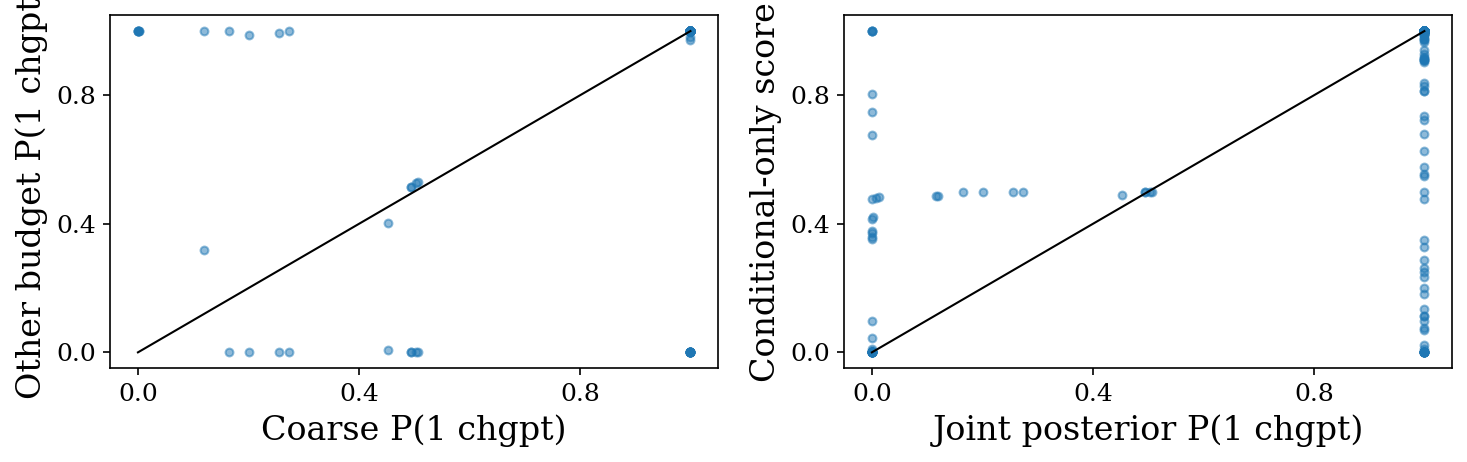

In [8]:

numerical=pd.read_csv(output/'numerical_refinement.csv')
numerical['meets_updated_target']=(numerical.P_1>.5)&(numerical.mass_above55>.5)
decomposition=pd.read_csv(output/'conditional_only_diagnostic.csv')
quadrature_check=pd.read_csv(output/'quadrature_check.csv')
print('Numerical budget comparison:')
with pd.option_context('display.max_rows',150):display(numerical)
print('Joint posterior versus conditional-only scoring (not interchangeable):')
with pd.option_context('display.max_rows',300):display(decomposition)
print('Largest absolute count probability change:',numerical.delta_P_1.abs().max())
print('Largest conditional-curve TV change:',numerical.TV_from_coarse.max())
print('Refined cases meeting both updated targets:')
display(numerical[numerical.meets_updated_target])
print('Independent 80-versus-160-node likelihood quadrature check:')
display(quadrature_check)
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
axes[0].scatter(numerical.coarse_P_1,numerical.P_1,s=14,alpha=.5)
axes[0].plot([0,1],[0,1],color='black',lw=1)
axes[0].set_xlabel('Coarse P(1 chgpt)');axes[0].set_ylabel('Other budget P(1 chgpt)')
axes[1].scatter(decomposition.joint_P_1,decomposition.conditional_only_P_1,s=14,alpha=.5)
axes[1].plot([0,1],[0,1],color='black',lw=1)
axes[1].set_xlabel('Joint posterior P(1 chgpt)');axes[1].set_ylabel('Conditional-only score')
for ax in axes:ax.xaxis.set_major_locator(ticker.MaxNLocator(3));ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
fig.tight_layout();plt.show()


## Denser penalty exploration

To resolve sensitivity between the initial penalty choices, use 13 logarithmically spaced L2
strengths from $10^{-9}$ to $10^{-3}$ and nine L1 strengths from $10^{-7}$ to $10^{-3}$.
Keep $\Delta=1$ and compare all five LS covariance estimates and the moderate-ridge auxiliary
estimate at 3 and 30 updates. Reuse the **512-draw, 100-evaluation** refined states and use 160-node
likelihood quadrature. This is 154 additional comparisons; none changes the prior odds.


In [9]:
"""Denser posterior-penalty grid reusing already computed state equations."""


SWEEP_FITS=[('l2',float(x)) for x in np.logspace(-9,-3,13)]+[('l1',float(x)) for x in np.logspace(-7,-3,9)]


def sweep_fit(spec,X,y,phi,root):
    kind,strength=spec;name=f'{kind}_{strength:.8g}'
    path=root/('fit_'+name+'.pkl')
    if path.exists():return name,pickle.load(path.open('rb'))
    try:fit=fit_logistic(X,y,phi,kind,strength)
    except Exception as error:fit=dict(error=repr(error))
    atomic_save(path,fit);return name,fit


def sweep_case(rec,setting,name,fit,X,y,ages,root):
    label=rec['label']+'_'+name;path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    if 'error' in fit:return dict(label=label,error=fit['error'])
    values=[]
    for e,state in zip(rec['eta'],rec['states']):
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        values.append(gaussian_logistic_loglikelihood(fit['V'],y,rec['scenario']['rho'],
                       state['lambda'],state['kappa'],psi,quadrature_order=160))
    values=np.asarray(values);joint=values+np.log(setting['prior'])
    probabilities=np.exp(joint-logsumexp(joint));curve=np.exp(values[1:]-logsumexp(values[1:]))
    result=dict(label=label,base_setting=rec['label'],posterior_fit=name,
        penalty=fit['penalty'],strength=fit['strength'],P_1=float(probabilities[1:].sum()),
        conditional=curve,mass_above55=float(curve[ages[rec['eta'][1:]]>55].sum()),
        peak_age=float(ages[rec['eta'][1:][np.argmax(curve)]]),
        log_Bayes_factor=float(logsumexp(values[1:])-np.log(len(curve))-values[0]),
        max_fit_kkt=max(c['kkt'] for c in fit['checks']),FP_residual_max=max(rec['residuals']))
    atomic_save(path,result);return result


def penalty_sweep(output):
    X,y,ages,locations=load_data();setting=pickle.load((output/'fits_delta1.pkl').open('rb'))
    root=output/'denser_penalty_grid';root.mkdir(exist_ok=True)
    # All five LS covariance estimates and moderate-ridge auxiliary estimates
    # at 3/30 updates. Selection is by specification, not posterior outcomes.
    paths=[p for p in output.glob('d1*_q7_b40.pkl') if
           p.name.startswith('d1_least_squares_') or
           p.name in ['d1_l2_1e-06_it3_q7_b40.pkl','d1_l2_1e-06_it30_q7_b40.pkl']]
    fine_paths=[p.with_name(p.name.replace('_q7_b40','_q9_b100')) for p in paths]
    assert all(p.exists() for p in fine_paths), 'Run the declared numerical refinements first.'
    records=[pickle.load(p.open('rb')) for p in fine_paths]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        fits=Parallel(n_jobs=22)(delayed(sweep_fit)(spec,X,y,setting['phi'],root) for spec in SWEEP_FITS)
        results=Parallel(n_jobs=36)(delayed(sweep_case)(r,setting,name,fit,X,y,ages,root)
                    for r in records for name,fit in fits)
    pd.DataFrame([{k:v for k,v in r.items() if k!='conditional'} for r in results]).to_csv(root/'summary.csv',index=False)
    print('Denser penalty sweep complete:',len(results),'comparisons.',flush=True)
    return results



sweep_results=penalty_sweep(output)

Denser penalty sweep complete: 154 comparisons.


,label,base_setting,posterior_fit,penalty,strength,P_1,mass_above55,peak_age,log_Bayes_factor,max_fit_kkt,FP_residual_max,TV_to_reference,meets_updated_target
0,d1_l2_1e-06_it30_q9_b100_l2_1e-09,d1_l2_1e-06_it30_q9_b100,l2_1e-09,l2,1.000000e-09,1.000000,1.000000e+00,72.0,2.483043e+04,3.150017e-10,6.441803e-10,1.000000,True
1,d1_l2_1e-06_it30_q9_b100_l2_3.1622777e-09,d1_l2_1e-06_it30_q9_b100,l2_3.1622777e-09,l2,3.162278e-09,1.000000,1.000000e+00,73.0,1.553316e+04,1.458053e-09,6.441803e-10,0.999999,True
2,d1_l2_1e-06_it30_q9_b100_l2_1e-08,d1_l2_1e-06_it30_q9_b100,l2_1e-08,l2,1.000000e-08,1.000000,1.000000e+00,73.0,9.614368e+03,2.162753e-10,6.441803e-10,0.999999,True
3,d1_l2_1e-06_it30_q9_b100_l2_3.1622777e-08,d1_l2_1e-06_it30_q9_b100,l2_3.1622777e-08,l2,3.162278e-08,1.000000,1.000000e+00,74.0,5.879225e+03,2.313223e-10,6.441803e-10,0.999993,True
4,d1_l2_1e-06_it30_q9_b100_l2_1e-07,d1_l2_1e-06_it30_q9_b100,l2_1e-07,l2,1.000000e-07,1.000000,1.000000e+00,74.0,2.898035e+03,2.319271e-10,6.441803e-10,0.999993,True
5,d1_l2_1e-06_it30_q9_b100_l2_3.1622777e-07,d1_l2_1e-06_it30_q9_b100,l2_3.1622777e-07,l2,3.162278e-07,1.000000,1.000000e+00,72.0,1.049710e+03,4.983112e-11,6.441803e-10,0.999999,True
6,d1_l2_1e-06_it30_q9_b100_l2_1e-06,d1_l2_1e-06_it30_q9_b100,l2_1e-06,l2,1.000000e-06,1.000000,1.000000e+00,64.0,4.868702e+02,2.198373e-10,6.441803e-10,1.000000,True
7,d1_l2_1e-06_it30_q9_b100_l2_3.1622777e-06,d1_l2_1e-06_it30_q9_b100,l2_3.1622777e-06,l2,3.162278e-06,1.000000,4.415476e-03,54.0,5.846657e+02,5.812734e-10,6.441803e-10,1.000000,False
8,d1_l2_1e-06_it30_q9_b100_l2_1e-05,d1_l2_1e-06_it30_q9_b100,l2_1e-05,l2,1.000000e-05,1.000000,3.226983e-32,35.0,7.328523e+02,3.139155e-10,6.441803e-10,0.885094,False
9,d1_l2_1e-06_it30_q9_b100_l2_3.1622777e-05,d1_l2_1e-06_it30_q9_b100,l2_3.1622777e-05,l2,3.162278e-05,1.000000,3.225925e-54,38.0,8.725341e+02,3.000595e-10,6.441803e-10,0.903357,False


Closest refined curves among P(1)>0.5; exploratory ranking:


,label,base_setting,posterior_fit,penalty,strength,P_1,mass_above55,peak_age,log_Bayes_factor,max_fit_kkt,FP_residual_max,TV_to_reference,meets_updated_target
64,d1_least_squares_it30_q9_b100_l1_0.00031622777,d1_least_squares_it30_q9_b100,l1_0.00031622777,l1,0.000316,0.510370,6.153482e-01,69.0,0.041488,4.092001e-12,1.147679e-09,0.640760,True
53,d1_least_squares_it30_q9_b100_l2_3.1622777e-05,d1_least_squares_it30_q9_b100,l2_3.1622777e-05,l2,0.000032,0.508934,6.057862e-01,69.0,0.035741,3.000595e-10,1.147679e-09,0.642306,True
65,d1_least_squares_it30_q9_b100_l1_0.001,d1_least_squares_it30_q9_b100,l1_0.001,l1,0.001000,0.515914,6.118487e-01,67.0,0.063678,5.689013e-11,1.147679e-09,0.647770,True
54,d1_least_squares_it30_q9_b100_l2_0.0001,d1_least_squares_it30_q9_b100,l2_0.0001,l2,0.000100,0.514800,6.090208e-01,66.0,0.059216,6.733576e-11,1.147679e-09,0.647903,True
55,d1_least_squares_it30_q9_b100_l2_0.00031622777,d1_least_squares_it30_q9_b100,l2_0.00031622777,l2,0.000316,0.516352,6.103089e-01,66.0,0.065430,2.215809e-11,1.147679e-09,0.649050,True
56,d1_least_squares_it30_q9_b100_l2_0.001,d1_least_squares_it30_q9_b100,l2_0.001,l2,0.001000,0.516698,6.102752e-01,66.0,0.066818,4.035745e-11,1.147679e-09,0.649232,True
138,d1_least_squares_it3_q9_b100_l2_1e-06,d1_least_squares_it3_q9_b100,l2_1e-06,l2,0.000001,0.999980,1.000000e+00,87.0,10.810912,2.198373e-10,1.302944e-09,0.829919,True
72,d1_least_squares_it1_q9_b100_l2_1e-06,d1_least_squares_it1_q9_b100,l2_1e-06,l2,0.000001,1.000000,1.000000e+00,83.0,95.570251,2.198373e-10,8.632965e-10,0.860774,True
8,d1_l2_1e-06_it30_q9_b100_l2_1e-05,d1_l2_1e-06_it30_q9_b100,l2_1e-05,l2,0.000010,1.000000,3.226983e-32,35.0,732.852301,3.139155e-10,6.441803e-10,0.885094,False
119,d1_l2_1e-06_it3_q9_b100_l2_3.1622777e-05,d1_l2_1e-06_it3_q9_b100,l2_3.1622777e-05,l2,0.000032,1.000000,2.444327e-54,27.0,1252.935040,3.000595e-10,6.543817e-10,0.885162,False


Refined penalty settings meeting both updated targets:


,label,base_setting,posterior_fit,penalty,strength,P_1,mass_above55,peak_age,log_Bayes_factor,max_fit_kkt,FP_residual_max,TV_to_reference,meets_updated_target
64,d1_least_squares_it30_q9_b100_l1_0.00031622777,d1_least_squares_it30_q9_b100,l1_0.00031622777,l1,0.000316,0.510370,0.615348,69.0,0.041488,4.092001e-12,1.147679e-09,0.640760,True
53,d1_least_squares_it30_q9_b100_l2_3.1622777e-05,d1_least_squares_it30_q9_b100,l2_3.1622777e-05,l2,0.000032,0.508934,0.605786,69.0,0.035741,3.000595e-10,1.147679e-09,0.642306,True
65,d1_least_squares_it30_q9_b100_l1_0.001,d1_least_squares_it30_q9_b100,l1_0.001,l1,0.001000,0.515914,0.611849,67.0,0.063678,5.689013e-11,1.147679e-09,0.647770,True
54,d1_least_squares_it30_q9_b100_l2_0.0001,d1_least_squares_it30_q9_b100,l2_0.0001,l2,0.000100,0.514800,0.609021,66.0,0.059216,6.733576e-11,1.147679e-09,0.647903,True
55,d1_least_squares_it30_q9_b100_l2_0.00031622777,d1_least_squares_it30_q9_b100,l2_0.00031622777,l2,0.000316,0.516352,0.610309,66.0,0.065430,2.215809e-11,1.147679e-09,0.649050,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,d1_least_squares_it1_q9_b100_l1_0.00031622777,d1_least_squares_it1_q9_b100,l1_0.00031622777,l1,0.000316,1.000000,1.000000,67.0,273.932307,4.092001e-12,8.632965e-10,1.000000,True
74,d1_least_squares_it1_q9_b100_l2_1e-05,d1_least_squares_it1_q9_b100,l2_1e-05,l2,0.000010,1.000000,1.000000,67.0,407.139884,3.139155e-10,8.632965e-10,1.000000,True
75,d1_least_squares_it1_q9_b100_l2_3.1622777e-05,d1_least_squares_it1_q9_b100,l2_3.1622777e-05,l2,0.000032,1.000000,1.000000,66.0,322.510660,3.000595e-10,8.632965e-10,1.000000,True
6,d1_l2_1e-06_it30_q9_b100_l2_1e-06,d1_l2_1e-06_it30_q9_b100,l2_1e-06,l2,0.000001,1.000000,1.000000,64.0,486.870208,2.198373e-10,6.441803e-10,1.000000,True


Posterior penalty: l2


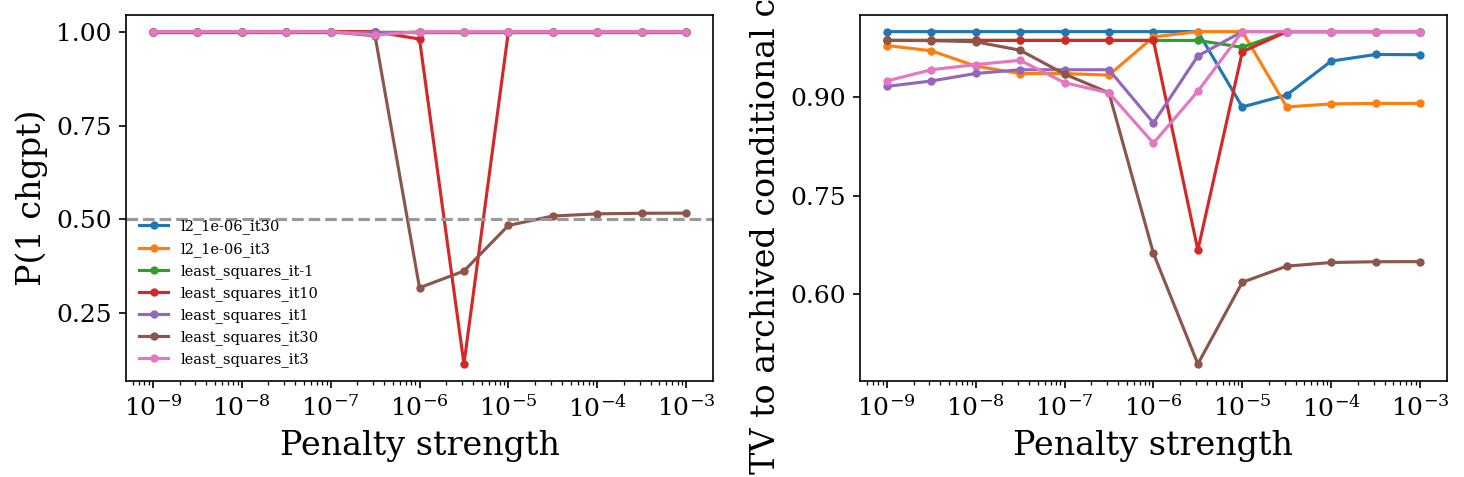

Posterior penalty: l1


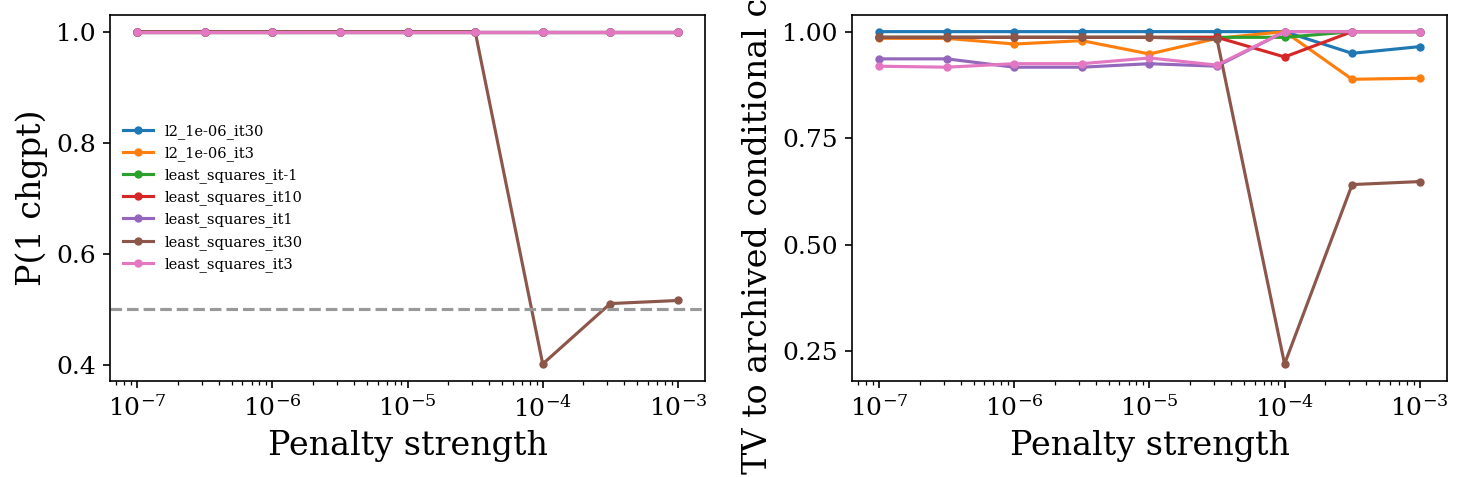

d1_least_squares_it30_q9_b100_l1_0.0001 P(1)= 0.40162068846654075 TV= 0.21942220751369756


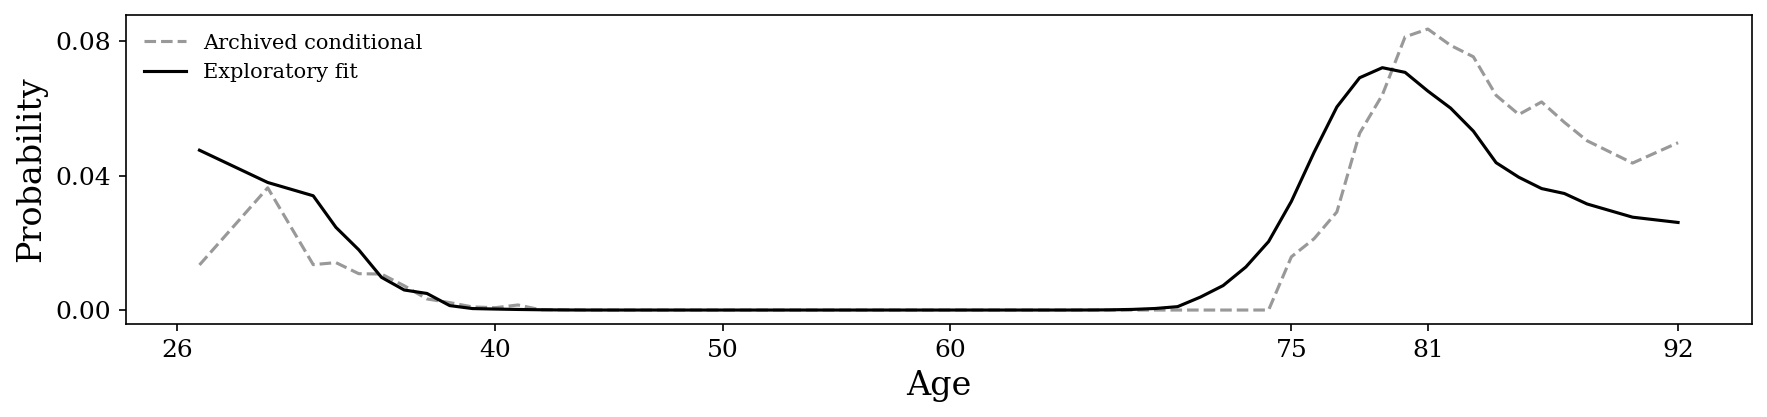

d1_least_squares_it30_q9_b100_l2_3.1622777e-06 P(1)= 0.36252593051994497 TV= 0.49314136750257737


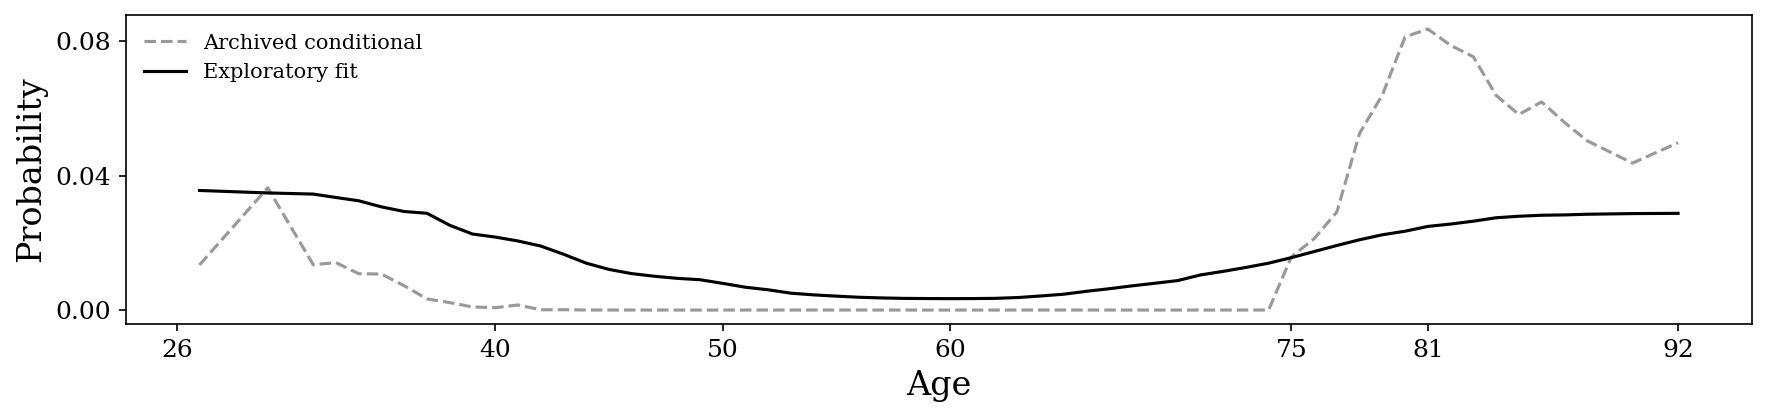

d1_least_squares_it30_q9_b100_l2_1e-05 P(1)= 0.48392456128419586 TV= 0.6177490056585887


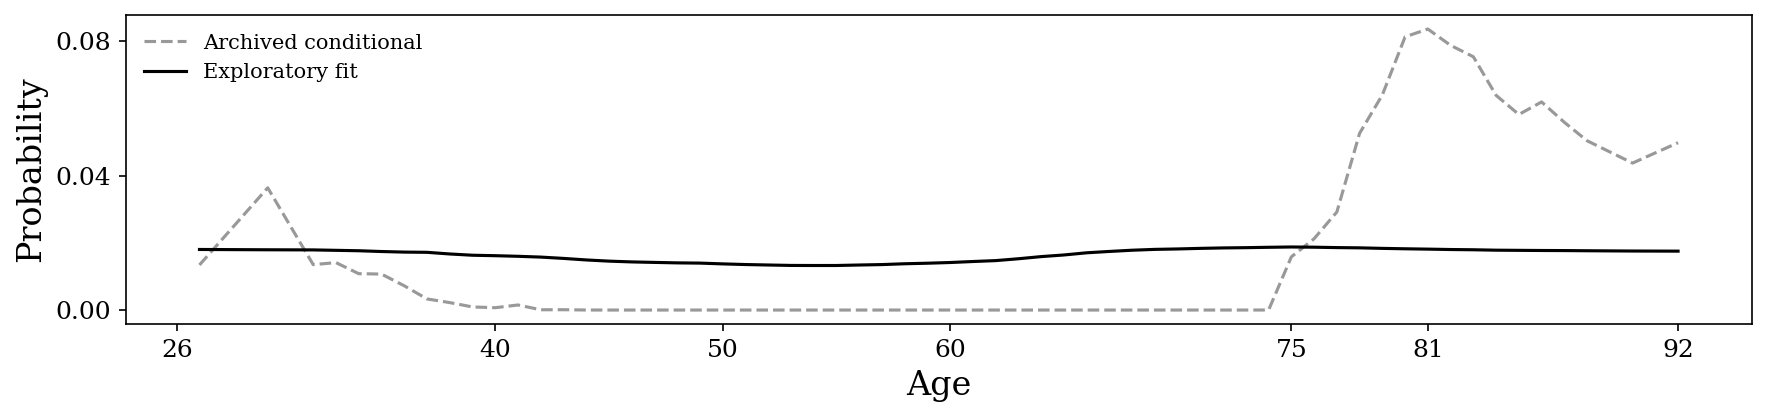

In [10]:

sweep_rows=[]
for r in sweep_results:
    row={k:v for k,v in r.items() if k!='conditional'}
    if 'error' not in r:
        row['TV_to_reference']=.5*np.abs(r['conditional']-np.array([reference_map[a] for a in ages[locations]])).sum()
    sweep_rows.append(row)
sweep_summary=pd.DataFrame(sweep_rows)
sweep_summary['meets_updated_target']=(sweep_summary.P_1>.5)&(sweep_summary.mass_above55>.5)
sweep_summary.to_csv(output/'denser_penalty_grid'/'summary_with_reference.csv',index=False)
with pd.option_context('display.max_rows',200):display(sweep_summary)
print('Closest refined curves among P(1)>0.5; exploratory ranking:')
display(sweep_summary[sweep_summary.P_1>.5].sort_values('TV_to_reference').head(15))
print('Refined penalty settings meeting both updated targets:')
display(sweep_summary[sweep_summary.meets_updated_target].sort_values('TV_to_reference'))
for kind in ('l2','l1'):
    print('Posterior penalty:',kind)
    fig,axes=plt.subplots(1,2,figsize=(10,3.4))
    for name,part in sweep_summary[sweep_summary.penalty==kind].groupby('base_setting'):
        part=part.sort_values('strength')
        axes[0].semilogx(part.strength,part.P_1,'.-',label=name.replace('d1_','').replace('_q9_b100',''))
        axes[1].semilogx(part.strength,part.TV_to_reference,'.-')
    axes[0].axhline(.5,color='.6',ls='--');axes[0].set_ylabel('P(1 chgpt)')
    axes[1].set_ylabel('TV to archived conditional curve')
    axes[0].legend(fontsize=7,frameon=False)
    for ax in axes:ax.set_xlabel('Penalty strength');ax.yaxis.set_major_locator(ticker.MaxNLocator(4))
    fig.tight_layout();plt.show()
for row in sweep_summary.sort_values('TV_to_reference').head(3).itertuples():
    r=next(r for r in sweep_results if r['label']==row.label)
    print(row.label,'P(1)=',row.P_1,'TV=',row.TV_to_reference)
    fig,ax=plt.subplots(figsize=(12,3))
    ax.plot(reference_ages,reference_weights,color='.6',ls='--',label='Archived conditional')
    ax.plot(ages[locations],r['conditional'],color='black',lw=1.5,label='Exploratory fit')
    ax.set_xlabel('Age');ax.set_ylabel('Probability');ax.set_xticks([26,40,50,60,75,81,92])
    ax.yaxis.set_major_locator(ticker.MaxNLocator(3));ax.legend(fontsize=10,frameon=False)
    fig.tight_layout();plt.show()


## Independent-draw follow-up

After inspecting the grid, follow up the LS 3-update (sharper) and 30-update (diffuse) cases
with a fixed independent seed 123 and 1,024 draws. This is an explicitly outcome-informed
follow-up, not another seed search. All 22 posterior penalties are reevaluated at both settings.
The uniform conditional age-grid prior already puts more than half its mass above 55;
meeting that location criterion alone need not imply concentration beyond the prior.


In [11]:
"""Outcome-disclosed follow-up using independent QMC draws, not a new search."""



def independent_state(rho,phi,e,n,delta,offset_rate=None):
    psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
    if offset_rate is not None:
        from WERM.myocardial_intercept import logistic_intercept_state
        return logistic_intercept_state(rho,phi,psi,delta,offset_rate,sample_power=10,max_nfev=100,seed=123)
    import WERM.myocardial_approximate as m
    from WERM.myocardial_numerics import logistic_prox_fast
    original=m.logistic_prox;m.logistic_prox=logistic_prox_fast
    try:return m.logistic_state(rho,phi,psi,delta,sample_power=10,max_nfev=100,seed=123)
    finally:m.logistic_prox=original


def check_baseline(root):
    X,y,ages,locations=load_data();setting=pickle.load((root/'fits_delta1.pkl').open('rb'))
    eta=setting['eta'];phi=setting['phi'];rows=[]
    for iteration in (3,30):
        case=f'd1_least_squares_it{iteration}_q9_b100'
        old=pickle.load((root/(case+'.pkl')).open('rb'));rho=old['scenario']['rho']
        out=root/(case+'_independent_seed123_q10.pkl')
        if out.exists():states=pickle.load(out.open('rb'))
        else:
            with parallel_config(backend='loky',inner_max_num_threads=1):
                states=Parallel(n_jobs=18)(delayed(independent_state)(rho,phi,e,len(y),len(y)/X.shape[1]) for e in eta)
            atomic_save(out,states)
        for path in (root/'denser_penalty_grid').glob('fit_*.pkl'):
            name=path.stem[4:];fit=pickle.load(path.open('rb'))
            if 'error' in fit:continue
            ll=[]
            for e,state in zip(eta,states):
                psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
                ll.append(gaussian_logistic_loglikelihood(fit['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160))
            ll=np.asarray(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
            reference=pickle.load((root/'denser_penalty_grid'/(case+'_'+name+'.pkl')).open('rb'))
            rows.append(dict(case=case,posterior_fit=name,P_1=probs[1:].sum(),mass_above55=curve[ages[eta[1:]]>55].sum(),
                original_P_1=reference['P_1'],original_mass_above55=reference['mass_above55'],
                TV_from_original=.5*np.abs(curve-reference['conditional']).sum(),
                peak_age=ages[eta[1:][np.argmax(curve)]],FP_residual_max=max(s['training_residual'] for s in states)))
            atomic_save(root/'denser_penalty_grid'/(case+'_'+name+'_independent.pkl'),dict(conditional=curve,log_likelihood=ll,**rows[-1]))
    pd.DataFrame(rows).to_csv(root/'independent_draw_check.csv',index=False)
    print('Independent-draw follow-up complete.',flush=True)


def check_intercept(root):
    from WERM.myocardial_intercept import intercept_loglikelihood
    X,y,ages,locations=load_data();setting=pickle.load((root/'offset_fits.pkl').open('rb'))
    eta=setting['eta'];phi=setting['phi'];rows=[]
    for iteration in (10,30):
        case=f'offset_l1_0.0001_it{iteration}_q9_b100'
        old=pickle.load((root/(case+'.pkl')).open('rb'));rho=old['scenario']['rho']
        out=root/(case+'_independent_seed123_q10.pkl')
        if out.exists():states=pickle.load(out.open('rb'))
        else:
            with parallel_config(backend='loky',inner_max_num_threads=1):
                states=Parallel(n_jobs=18)(delayed(independent_state)(rho,phi,e,len(y),len(y)/X.shape[1],setting['rate']) for e in eta)
            atomic_save(out,states)
        for name,fit in setting['fits'].items():
            ll=[]
            for e,state in zip(eta,states):
                psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
                ll.append(intercept_loglikelihood(fit['V'],y,rho,state,psi))
            ll=np.asarray(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
            reference=old['results'][name]
            rows.append(dict(case=case,posterior_fit=name,P_1=probs[1:].sum(),mass_above55=curve[ages[eta[1:]]>55].sum(),
                original_P_1=reference['P_1'],original_mass_above55=reference['mass_above55'],
                TV_from_original=.5*np.abs(curve-reference['conditional']).sum(),
                peak_age=ages[eta[1:][np.argmax(curve)]],FP_residual_max=max(s['training_residual'] for s in states)))
            atomic_save(root/(case+'_'+name+'_independent.pkl'),dict(conditional=curve,log_likelihood=ll,**rows[-1]))
    pd.DataFrame(rows).to_csv(root/'independent_draw_check.csv',index=False)
    print('Intercept independent-draw follow-up complete.',flush=True)



check_baseline(output)

Independent-draw follow-up complete.


Conditional prior mass above age 55: 0.5737704918032787


,case,posterior_fit,P_1,mass_above55,original_P_1,original_mass_above55,TV_from_original,peak_age,FP_residual_max
0,d1_least_squares_it3_q9_b100,l2_3.1622777e-07,0.881978,1.000000e+00,0.990870,1.000000e+00,3.860633e-01,92.0,1.292123e-09
1,d1_least_squares_it3_q9_b100,l1_3.1622777e-06,1.000000,1.000000e+00,1.000000,1.000000e+00,2.722093e-227,83.0,1.292123e-09
2,d1_least_squares_it3_q9_b100,l2_3.1622777e-09,1.000000,1.000000e+00,1.000000,1.000000e+00,3.964155e-17,85.0,1.292123e-09
3,d1_least_squares_it3_q9_b100,l1_0.00031622777,1.000000,1.000000e+00,1.000000,1.000000e+00,2.865041e-02,67.0,1.292123e-09
4,d1_least_squares_it3_q9_b100,l2_1e-05,1.000000,1.000000e+00,1.000000,1.000000e+00,1.799545e-02,68.0,1.292123e-09
5,d1_least_squares_it3_q9_b100,l2_0.0001,1.000000,1.000000e+00,1.000000,1.000000e+00,2.835688e-02,66.0,1.292123e-09
6,d1_least_squares_it3_q9_b100,l1_1e-05,1.000000,1.000000e+00,1.000000,1.000000e+00,1.398500e-03,86.0,1.292123e-09
7,d1_least_squares_it3_q9_b100,l2_3.1622777e-06,1.000000,1.000000e+00,1.000000,1.000000e+00,8.154921e-03,78.0,1.292123e-09
8,d1_least_squares_it3_q9_b100,l1_3.1622777e-05,1.000000,1.000000e+00,1.000000,1.000000e+00,9.271188e-89,82.0,1.292123e-09
9,d1_least_squares_it3_q9_b100,l1_1e-06,1.000000,1.000000e+00,1.000000,1.000000e+00,1.035081e-200,83.0,1.292123e-09


d1_least_squares_it3_q9_b100 l2_1e-06 P(1): 0.9999798222948796 0.999884171973343


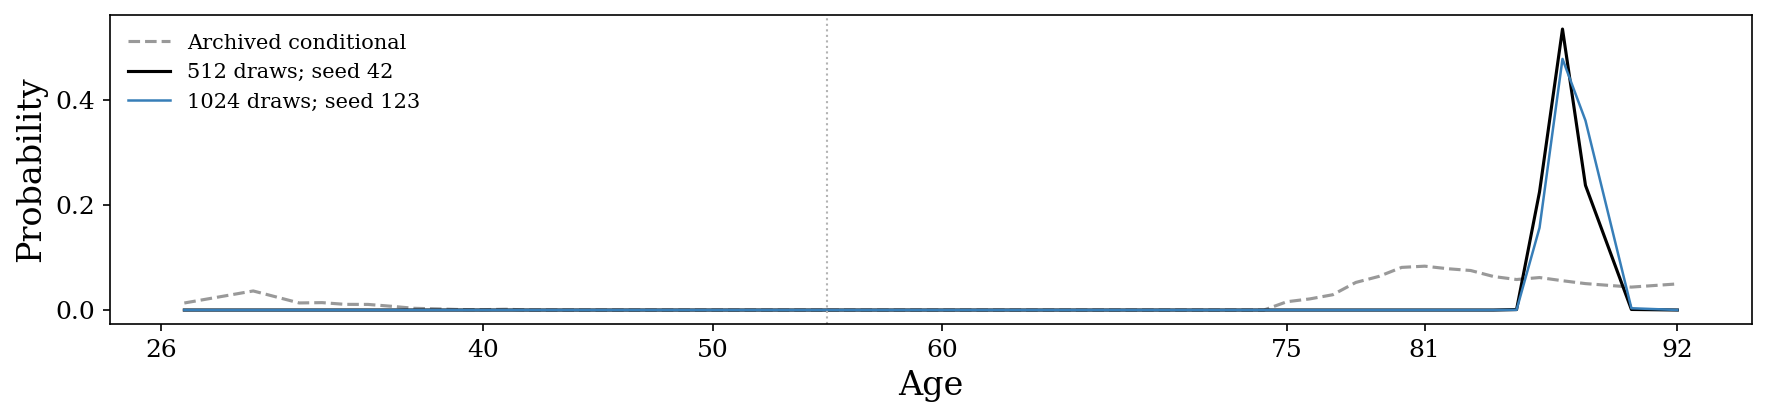

d1_least_squares_it30_q9_b100 l1_0.00031622777 P(1): 0.5103704345597154 0.5243972237773958


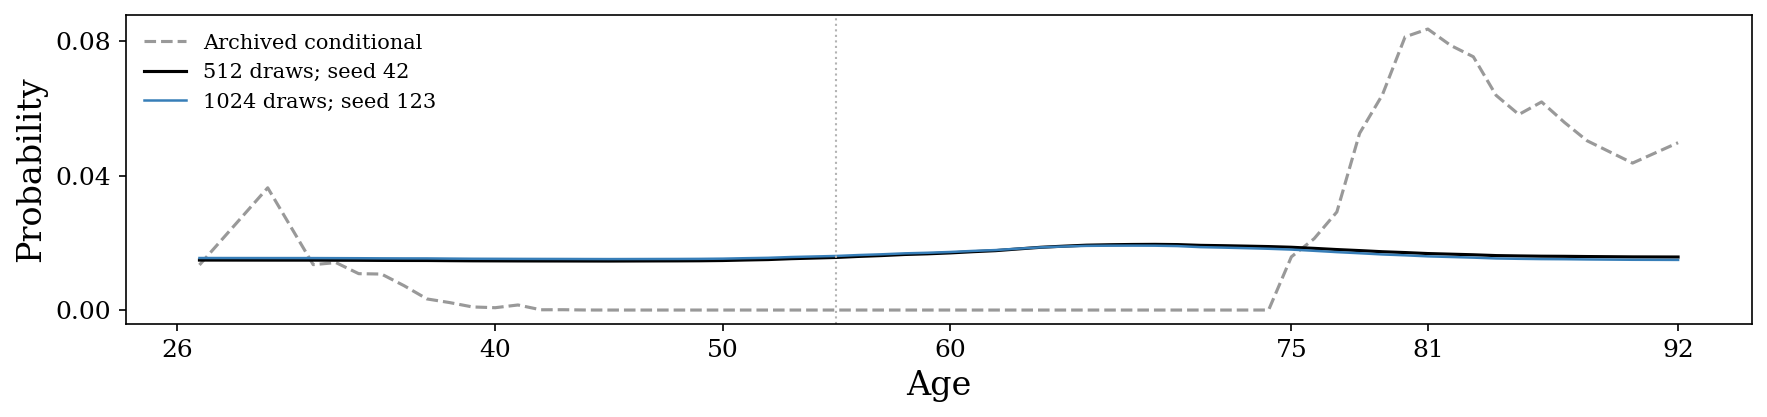

In [12]:

validation=pd.read_csv(output/'independent_draw_check.csv')
print('Conditional prior mass above age 55:',np.mean(ages[locations]>55))
with pd.option_context('display.max_rows',60):display(validation)
for iteration,name in [(3,'l2_1e-06'),(30,'l1_0.00031622777')]:
    case=f'd1_least_squares_it{iteration}_q9_b100'
    primary=pickle.load((output/'denser_penalty_grid'/(case+'_'+name+'.pkl')).open('rb'))
    independent=pickle.load((output/'denser_penalty_grid'/(case+'_'+name+'_independent.pkl')).open('rb'))
    print(case,name,'P(1):',primary['P_1'],independent['P_1'])
    fig,ax=plt.subplots(figsize=(12,3))
    ax.plot(reference_ages,reference_weights,color='.6',ls='--',label='Archived conditional')
    ax.plot(ages[locations],primary['conditional'],color='black',lw=1.5,label='512 draws; seed 42')
    ax.plot(ages[locations],independent['conditional'],color='#377eb8',lw=1.2,label='1024 draws; seed 123')
    ax.axvline(55,color='.7',ls=':',lw=1);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.set_xticks([26,40,50,60,75,81,92]);ax.yaxis.set_major_locator(ticker.MaxNLocator(3));ax.legend(frameon=False,fontsize=10)
    fig.tight_layout();plt.show()
